# Loan Default Prediction : EDA + Logistic Regression

**Goal:** Predict whether a loan applicant will **default** (1) or **repay** (0).

**Steps in this notebook**
1. Load the data
2. Clean the data (duplicates, missing values, wrong values)
3. EDA (charts)
4. Prepare the data (log transform, encoding)
5. Train-test split + StandardScaler
6. Logistic Regression model

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Data

In [2]:
df = pd.read_csv('loan_default_prediction.csv')
df.head()

,customer_id,age,gender,marital_status,education,employment_type,years_employed,annual_income,city_tier,residence_type,...,savings_balance,bank_relationship_years,loan_purpose,loan_amount,loan_term_months,interest_rate,monthly_emi,debt_to_income,has_cosigner,default
0,CUST103438,63,Female,Married,Graduate,Retired,NaN,124000.0,Tier 3,Owned,...,13800.0,0,Home,217000.0,120,11.26,3021.0,0.905,Yes,1
1,CUST106036,47,Male,Married,Post Graduate,Self-Employed,10.0,780000.0,Tier 1,Owned,...,97100.0,17,Home,1187000.0,120,11.67,16804.0,0.259,No,0
2,CUST116094,31,Male,Married,Graduate,Salaried,8.0,903000.0,Tier 3,Owned,...,944500.0,20,Business,1000000.0,24,9.40,45868.0,0.827,No,0
3,CUST114325,46,Male,Divorced,Post Graduate,Self-Employed,23.0,575000.0,Tier 3,Rented,...,107400.0,4,Business,1524000.0,48,9.25,38106.0,1.145,Yes,0
4,CUST115646,40,Male,Married,High School,Salaried,3.0,888000.0,Tier 1,Owned,...,22000.0,15,Home,4362000.0,120,13.21,65671.0,0.887,No,0


Number of rows and columns

In [3]:
df.shape

(25150, 25)

Column names, data types and non-null counts

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25150 entries, 0 to 25149
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              25150 non-null  str    
 1   age                      25150 non-null  int64  
 2   gender                   25150 non-null  str    
 3   marital_status           25150 non-null  str    
 4   education                24799 non-null  str    
 5   employment_type          25150 non-null  str    
 6   years_employed           24526 non-null  float64
 7   annual_income            24424 non-null  float64
 8   city_tier                25150 non-null  str    
 9   residence_type           25150 non-null  str    
 10  dependents               25150 non-null  int64  
 11  credit_score             24586 non-null  float64
 12  existing_loans           25150 non-null  int64  
 13  credit_utilization_pct   24611 non-null  float64
 14  late_payments_2yrs       25150 no

Basic statistics of numeric columns

In [5]:
df.describe()

,age,years_employed,annual_income,dependents,credit_score,existing_loans,credit_utilization_pct,late_payments_2yrs,savings_balance,bank_relationship_years,loan_amount,loan_term_months,interest_rate,monthly_emi,debt_to_income,default
count,25150.000000,24526.000000,2.442400e+04,25150.000000,24586.000000,25150.000000,24611.000000,25150.000000,2.418400e+04,25150.000000,2.515000e+04,25150.000000,25150.000000,2.515000e+04,25150.000000,25150.000000
mean,43.198449,9.197749,8.996663e+05,1.653042,712.248841,1.092684,43.745988,1.013598,5.262923e+05,9.956024,1.389416e+06,83.209861,12.298057,3.579487e+04,0.752065,0.303062
std,21.484414,9.381103,1.286423e+06,1.344457,75.447331,1.045297,21.262437,1.404244,5.705914e+05,6.036120,1.833518e+06,73.260545,3.218556,5.070393e+04,0.664638,0.459591
min,-5.000000,0.000000,2.200000e+04,0.000000,417.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,7.000000e+03,12.000000,7.500000,9.000000e+01,0.012000,0.000000
25%,32.000000,1.000000,4.120000e+05,0.000000,661.000000,0.000000,27.700000,0.000000,1.502000e+05,5.000000,3.710000e+05,36.000000,9.800000,9.267250e+03,0.343000,0.000000
50%,43.000000,6.000000,6.890000e+05,2.000000,712.000000,1.000000,42.500000,0.000000,3.521000e+05,10.000000,8.090000e+05,48.000000,12.110000,2.060800e+04,0.588000,0.000000
75%,54.000000,14.000000,1.108000e+06,3.000000,764.000000,2.000000,58.900000,2.000000,7.050000e+05,15.000000,1.678750e+06,120.000000,14.477500,4.339650e+04,0.949000,1.000000
max,999.000000,40.000000,7.750000e+07,5.000000,900.000000,8.000000,100.000000,13.000000,7.905400e+06,20.000000,4.509500e+07,240.000000,24.000000,2.044464e+06,13.802000,1.000000


## 3. Data Cleaning

### 3.1 Duplicate rows

In [6]:
df.duplicated().sum()

np.int64(150)

Remove the duplicate rows

In [7]:
df = df.drop_duplicates()
df.shape

(25000, 25)

### 3.2 Missing values

In [8]:
df.isnull().sum()

customer_id                  0
age                          0
gender                       0
marital_status               0
education                  351
employment_type              0
years_employed             618
annual_income              722
city_tier                    0
residence_type               0
dependents                   0
credit_score               557
existing_loans               0
credit_utilization_pct     537
late_payments_2yrs           0
savings_balance            957
bank_relationship_years      0
loan_purpose                 0
loan_amount                  0
loan_term_months             0
interest_rate                0
monthly_emi                  0
debt_to_income               0
has_cosigner                 0
default                      0
dtype: int64

Fill missing **numeric** values with the **median**

In [9]:
df['annual_income'] = df['annual_income'].fillna(df['annual_income'].median())
df['credit_score'] = df['credit_score'].fillna(df['credit_score'].median())
df['years_employed'] = df['years_employed'].fillna(df['years_employed'].median())
df['savings_balance'] = df['savings_balance'].fillna(df['savings_balance'].median())
df['credit_utilization_pct'] = df['credit_utilization_pct'].fillna(df['credit_utilization_pct'].median())

Fill missing **text** values with the **mode** (most common value)

In [10]:
df['education'] = df['education'].fillna(df['education'].mode()[0])

Check again – all values should be 0 now

In [11]:
df.isnull().sum()

customer_id                0
age                        0
gender                     0
marital_status             0
education                  0
employment_type            0
years_employed             0
annual_income              0
city_tier                  0
residence_type             0
dependents                 0
credit_score               0
existing_loans             0
credit_utilization_pct     0
late_payments_2yrs         0
savings_balance            0
bank_relationship_years    0
loan_purpose               0
loan_amount                0
loan_term_months           0
interest_rate              0
monthly_emi                0
debt_to_income             0
has_cosigner               0
default                    0
dtype: int64

### 3.3 Wrong values in `age`
Age should be between 18 and 80. Let's look at the wrong ones.

In [12]:
df[(df['age'] < 18) | (df['age'] > 80)]['age'].value_counts()

age
 0      8
 999    8
-5      5
 150    4
Name: count, dtype: int64

Keep only rows with a valid age

In [13]:
df = df[(df['age'] >= 18) & (df['age'] <= 80)]
df.shape

(24975, 25)

### 3.4 Inconsistent text values
`gender` has M / F mixed with Male / Female

In [14]:
df['gender'].value_counts()

gender
Male      15318
Female     9578
F            42
M            37
Name: count, dtype: int64

In [15]:
df['gender'] = df['gender'].replace({'M': 'Male', 'F': 'Female'})
df['gender'].value_counts()

gender
Male      15355
Female     9620
Name: count, dtype: int64

`employment_type` has some lowercase values like *salaried*

In [16]:
df['employment_type'].value_counts()

employment_type
Salaried          12815
Self-Employed      4976
Business Owner     3837
Retired            2062
Unemployed         1165
salaried             60
business owner       24
self-employed        23
retired               9
unemployed            4
Name: count, dtype: int64

In [17]:
df['employment_type'] = df['employment_type'].replace({
    'salaried': 'Salaried',
    'self-employed': 'Self-Employed',
    'business owner': 'Business Owner',
    'unemployed': 'Unemployed',
    'retired': 'Retired'
})
df['employment_type'].value_counts()

employment_type
Salaried          12875
Self-Employed      4999
Business Owner     3861
Retired            2071
Unemployed         1169
Name: count, dtype: int64

## 4. EDA (Exploratory Data Analysis)

### 4.1 Target column – `default`

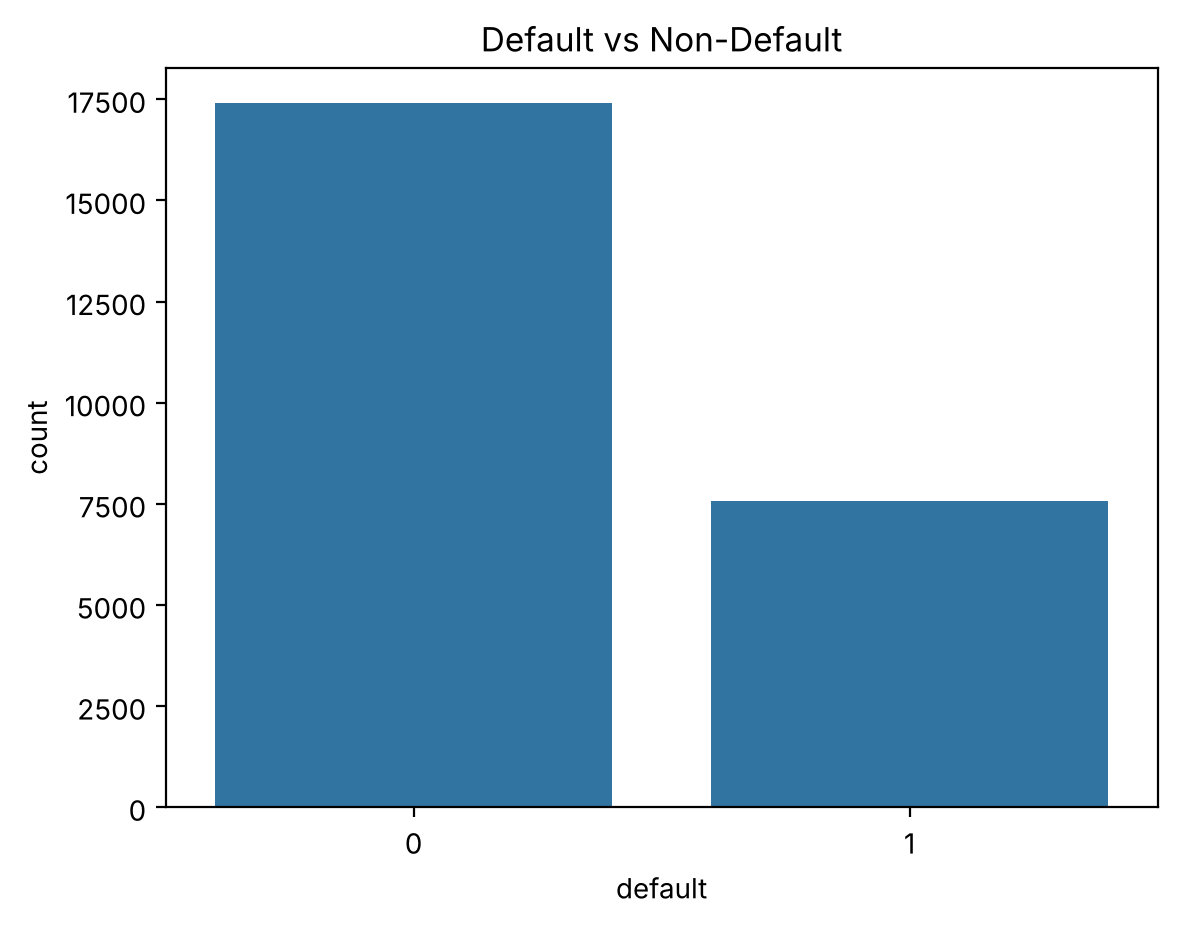

In [18]:
sns.countplot(x='default', data=df)
plt.title('Default vs Non-Default')
plt.show()

In [19]:
df['default'].value_counts(normalize=True) * 100

default
0    69.681682
1    30.318318
Name: proportion, dtype: float64

About **30%** of customers defaulted, so the data is slightly imbalanced.

### 4.2 Distribution of numeric columns

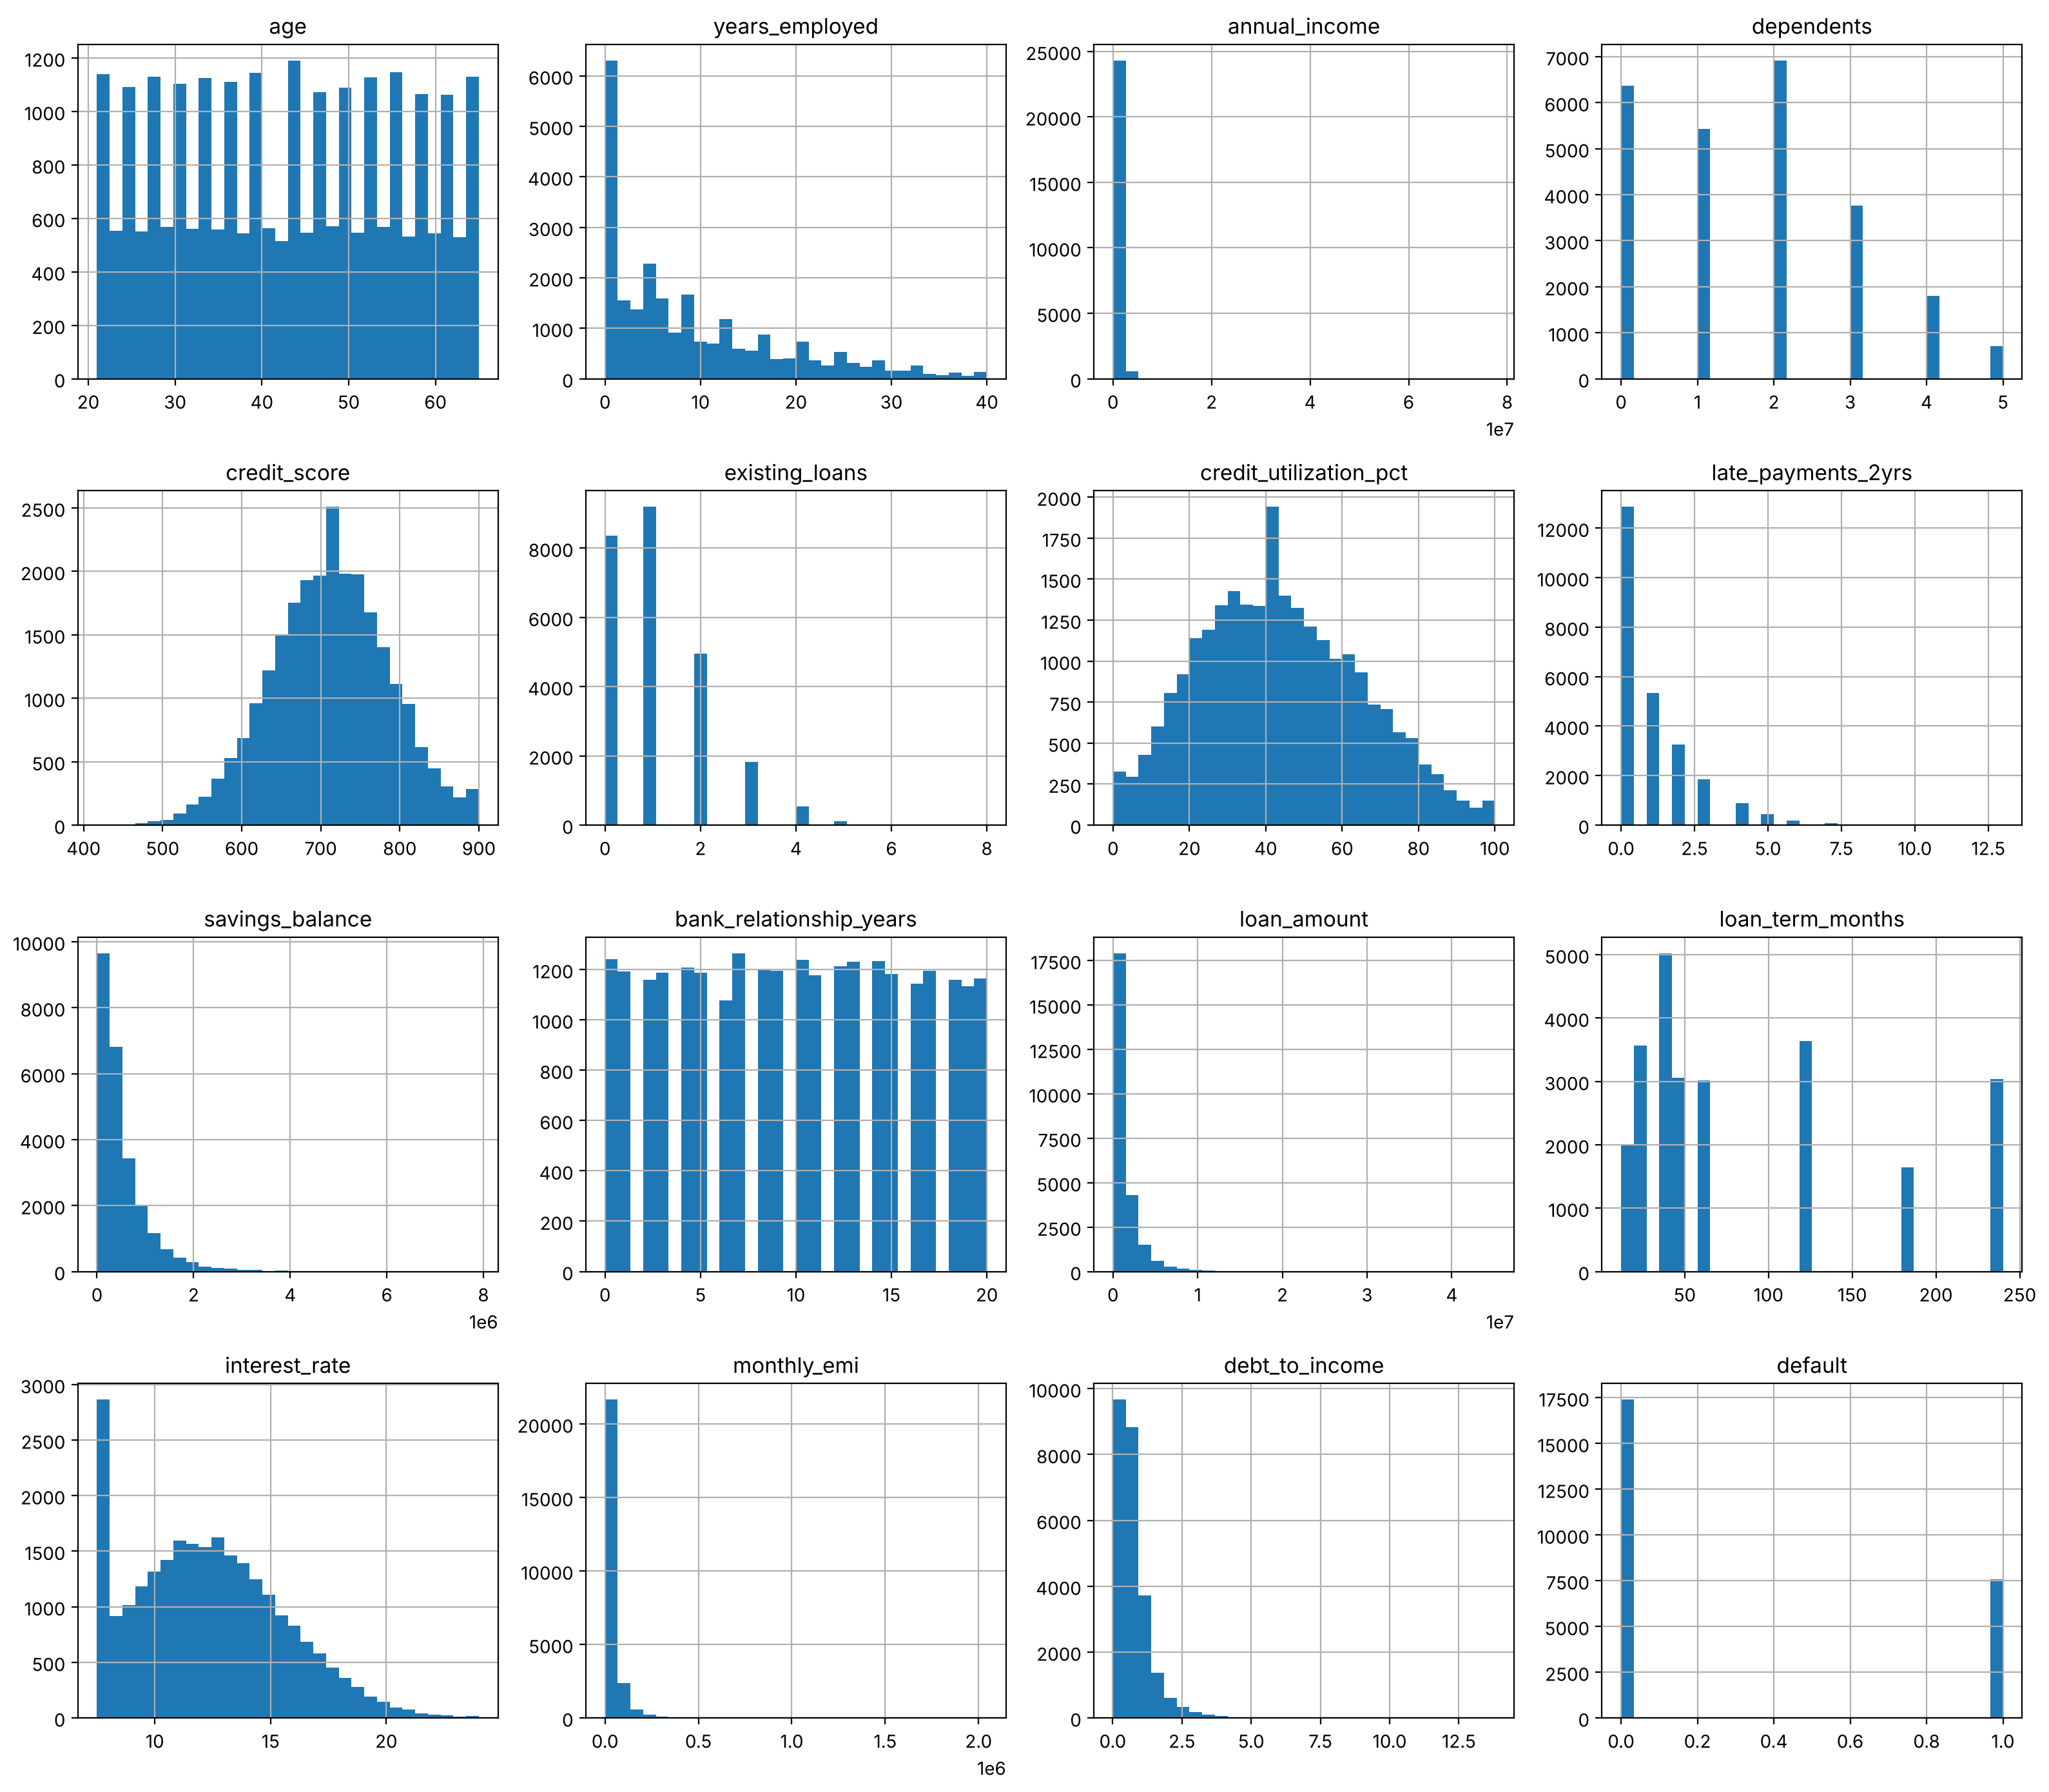

In [20]:
df.hist(figsize=(16, 14), bins=30)
plt.tight_layout()
plt.show()

`annual_income`, `loan_amount`, `savings_balance` and `monthly_emi` are **right-skewed**. We will apply a log transform later.

### 4.3 Outliers – Boxplots

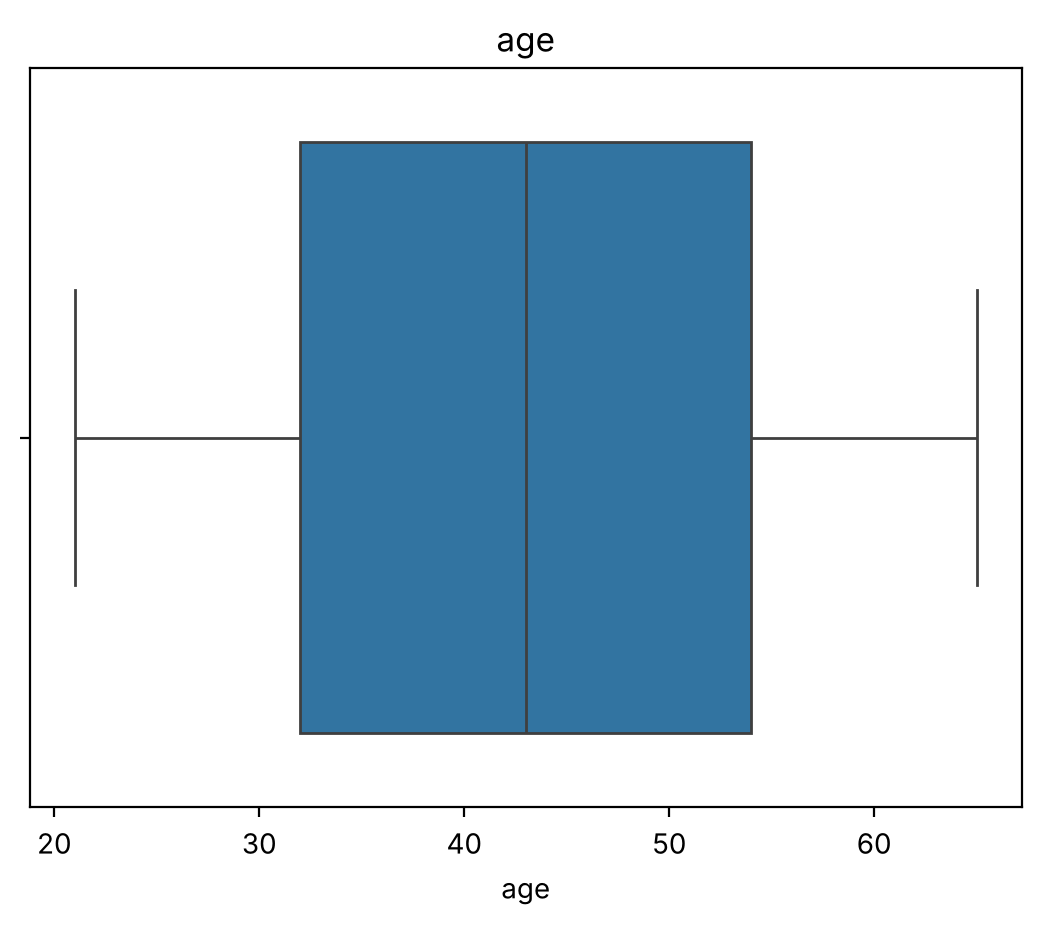

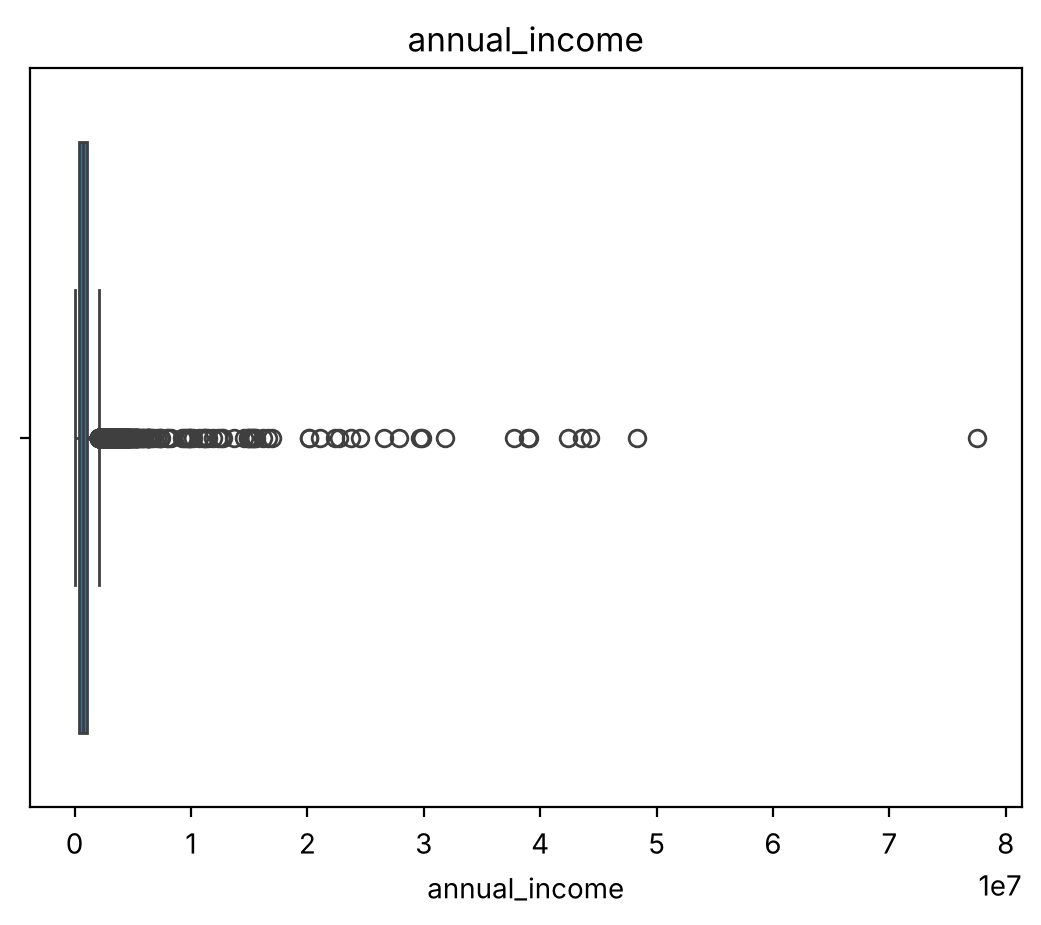

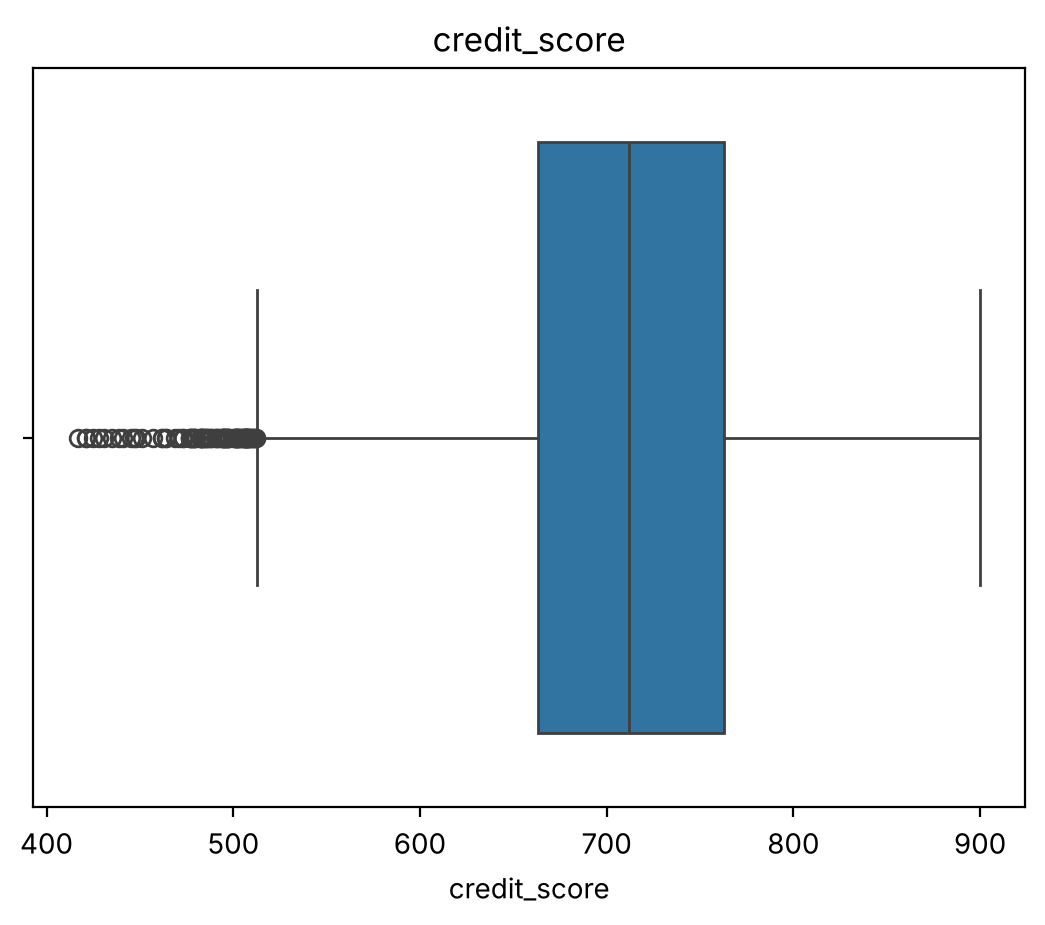

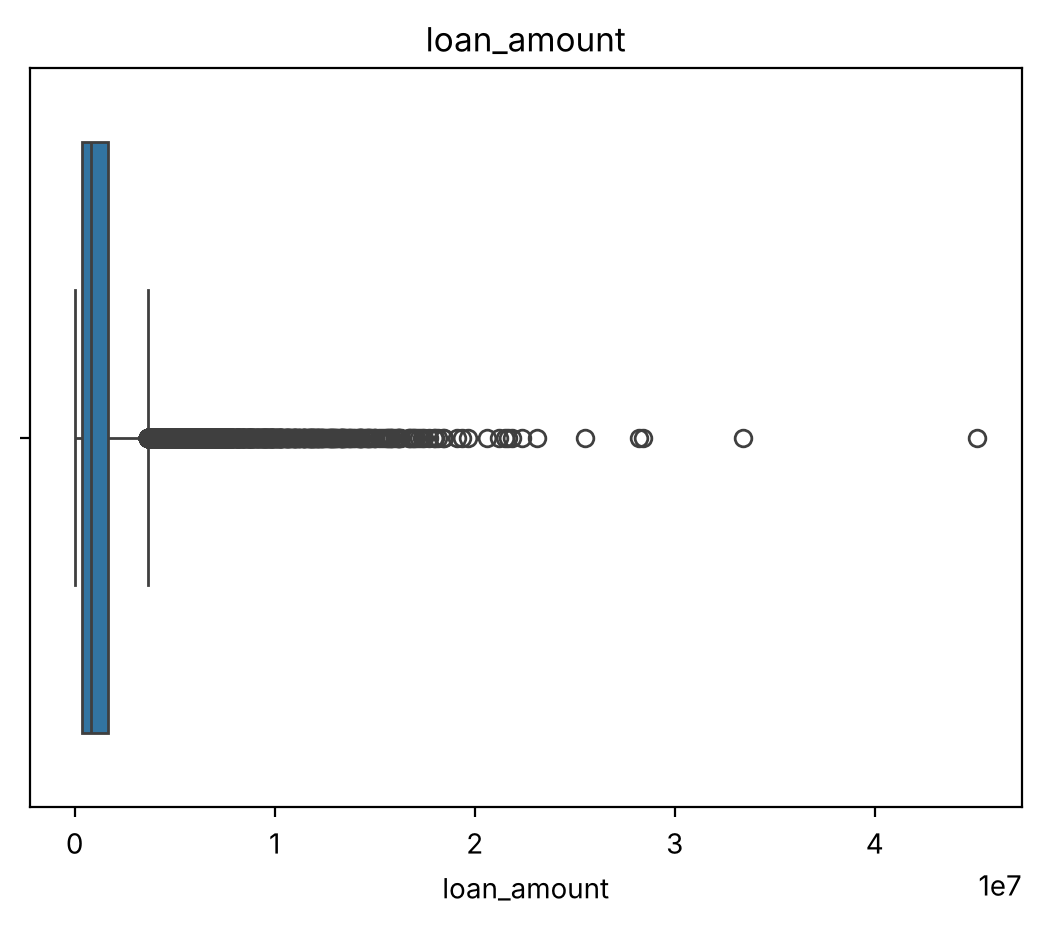

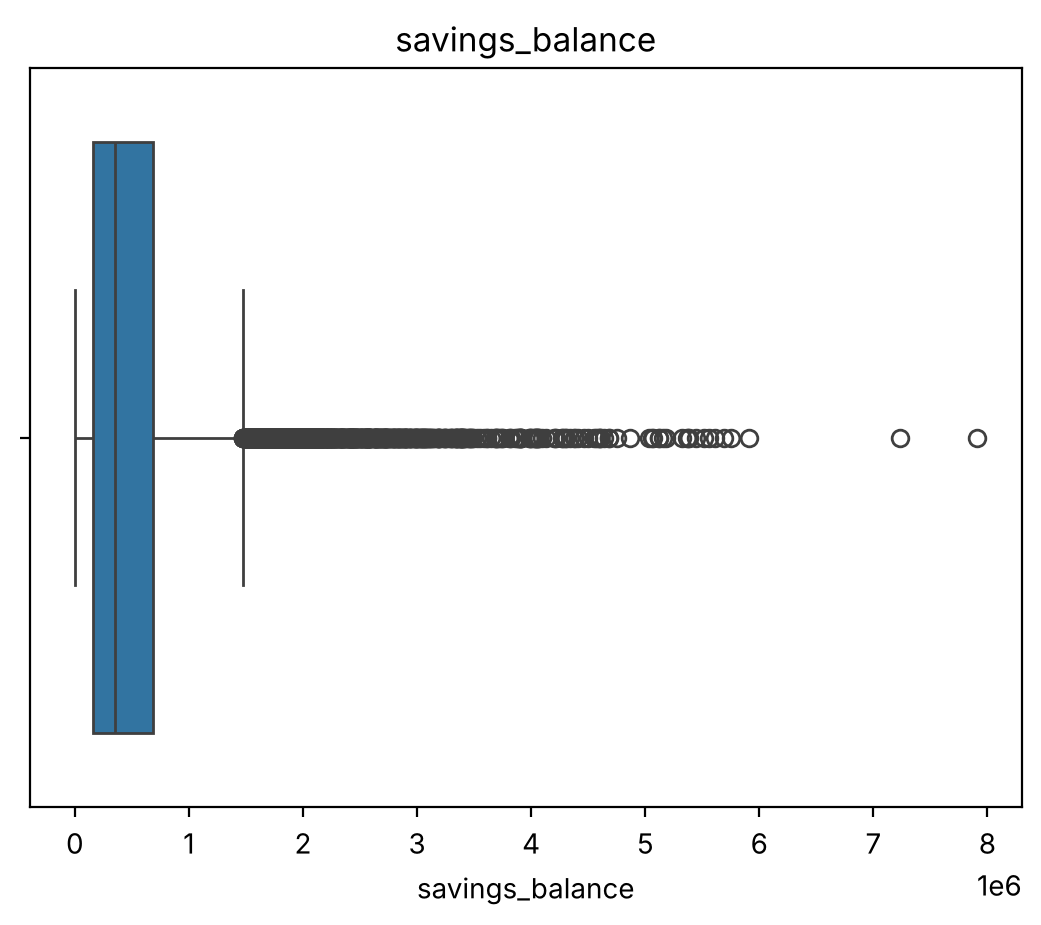

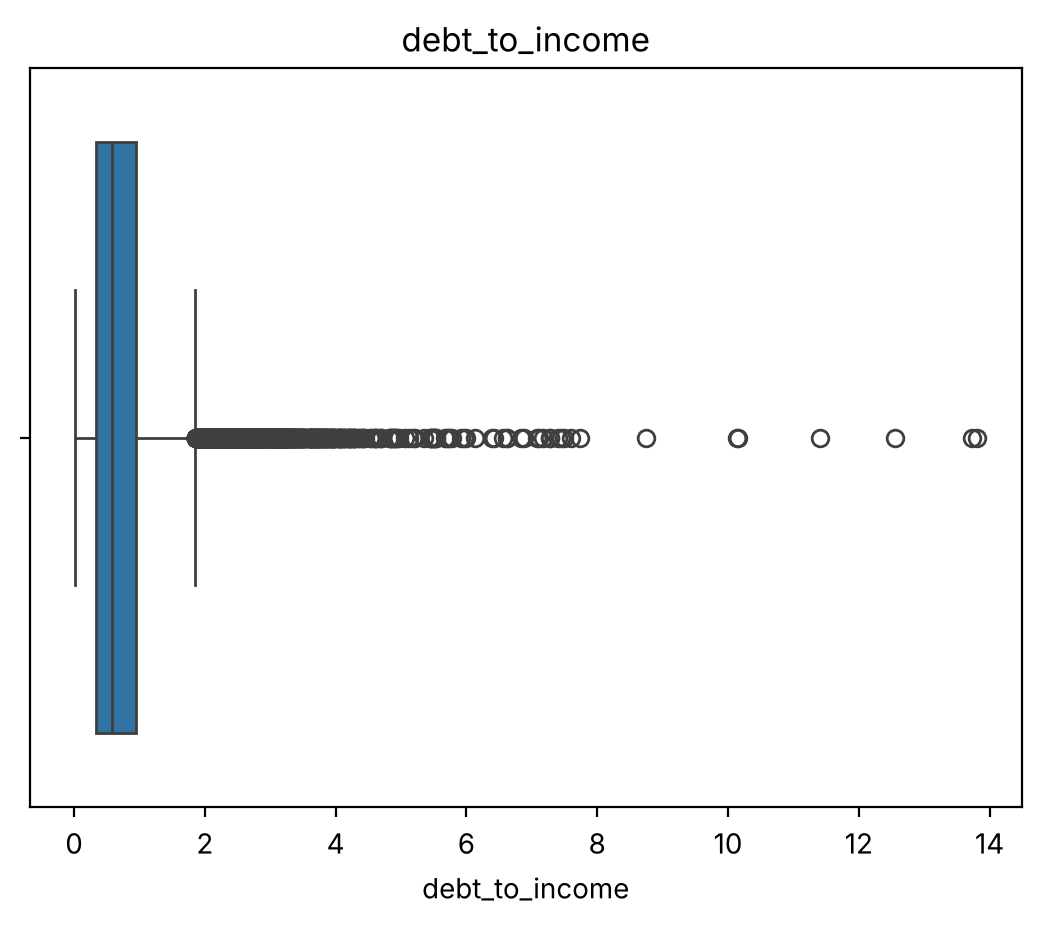

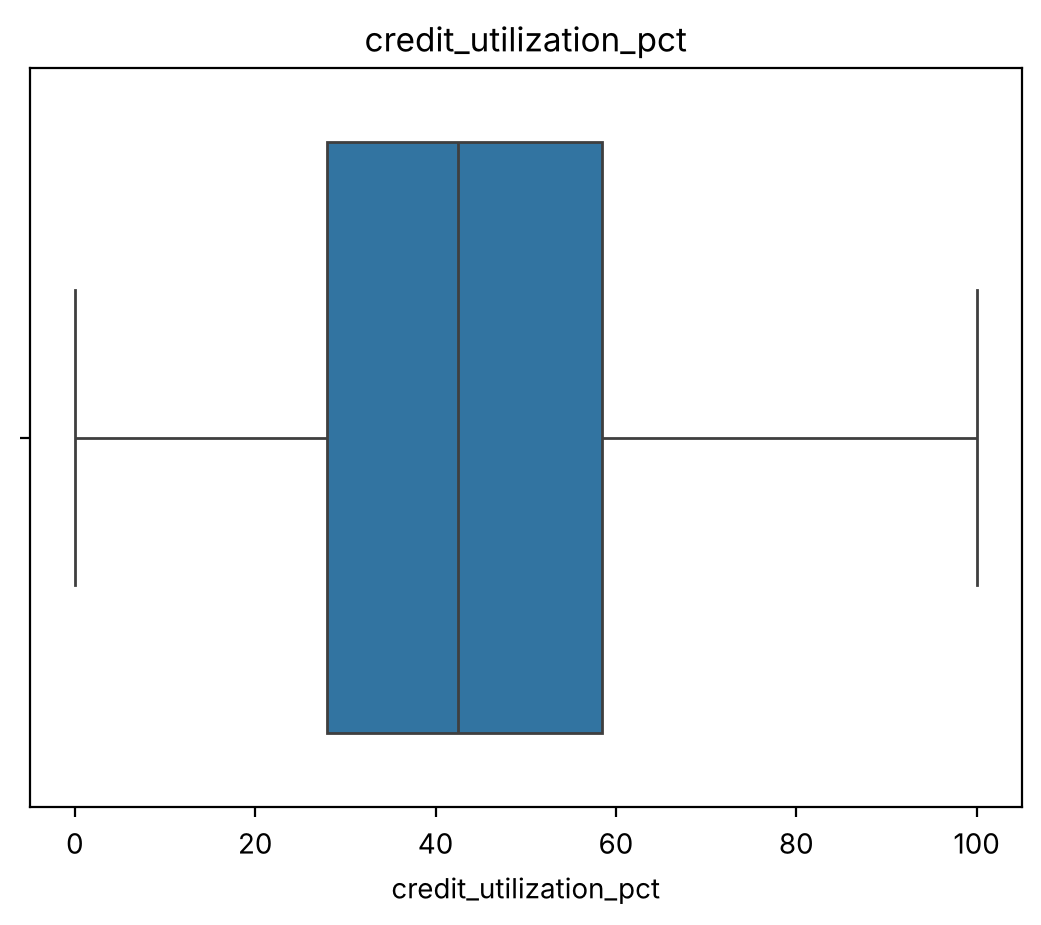

In [21]:
num_cols = ['age', 'annual_income', 'credit_score', 'loan_amount',
            'savings_balance', 'debt_to_income', 'credit_utilization_pct']

for col in num_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

`annual_income` has some very large outliers.
We cap them using the **IQR method**: any value above the upper limit is replaced by the upper limit.

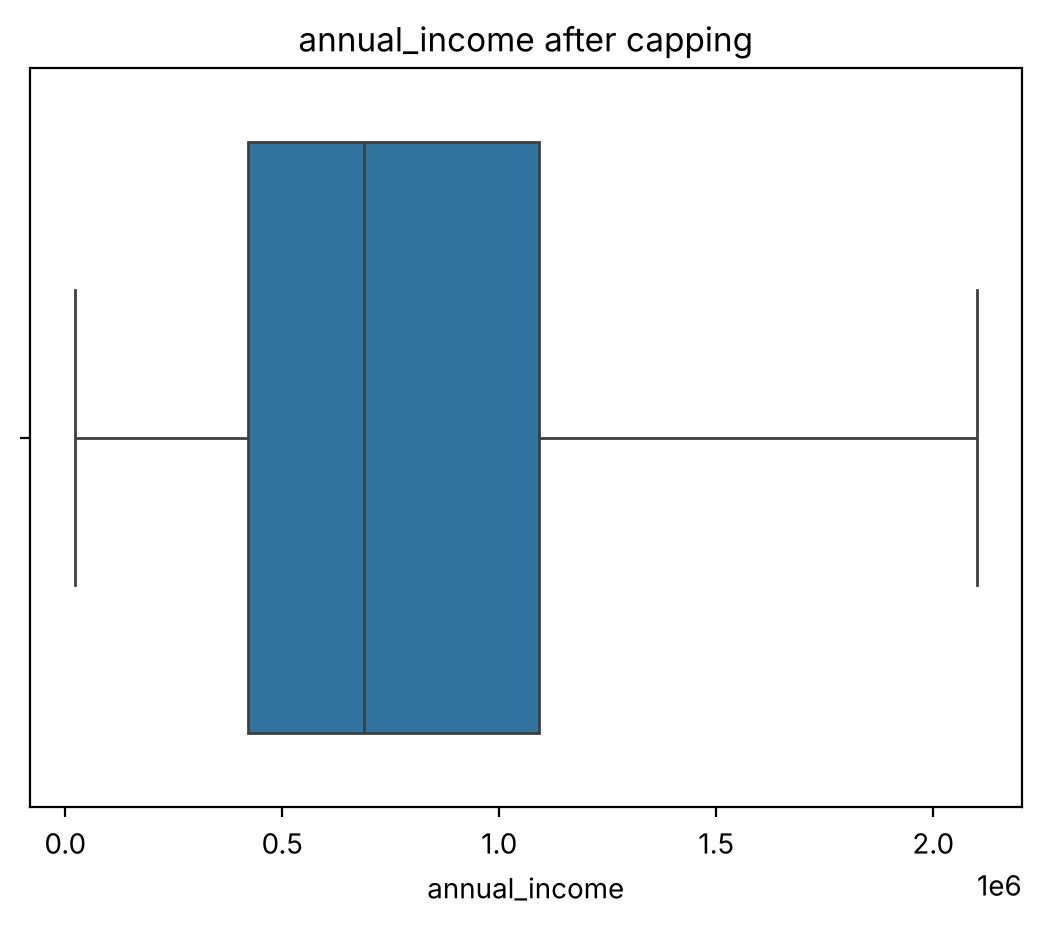

In [22]:
Q1 = df['annual_income'].quantile(0.25)
Q3 = df['annual_income'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

df['annual_income'] = np.where(df['annual_income'] > upper_limit, upper_limit, df['annual_income'])

sns.boxplot(x=df['annual_income'])
plt.title('annual_income after capping')
plt.show()

### 4.4 Categorical columns vs Default

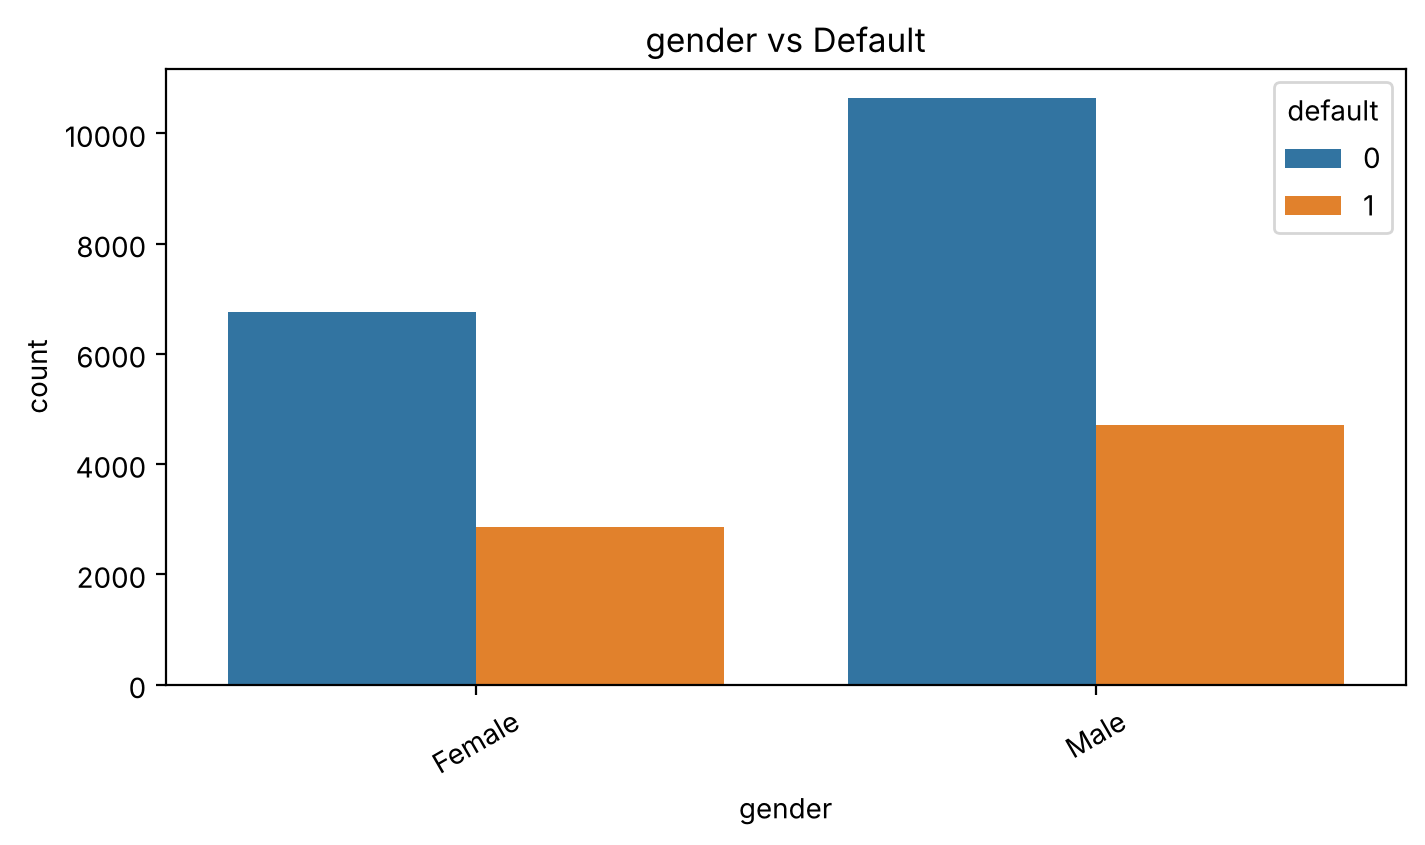

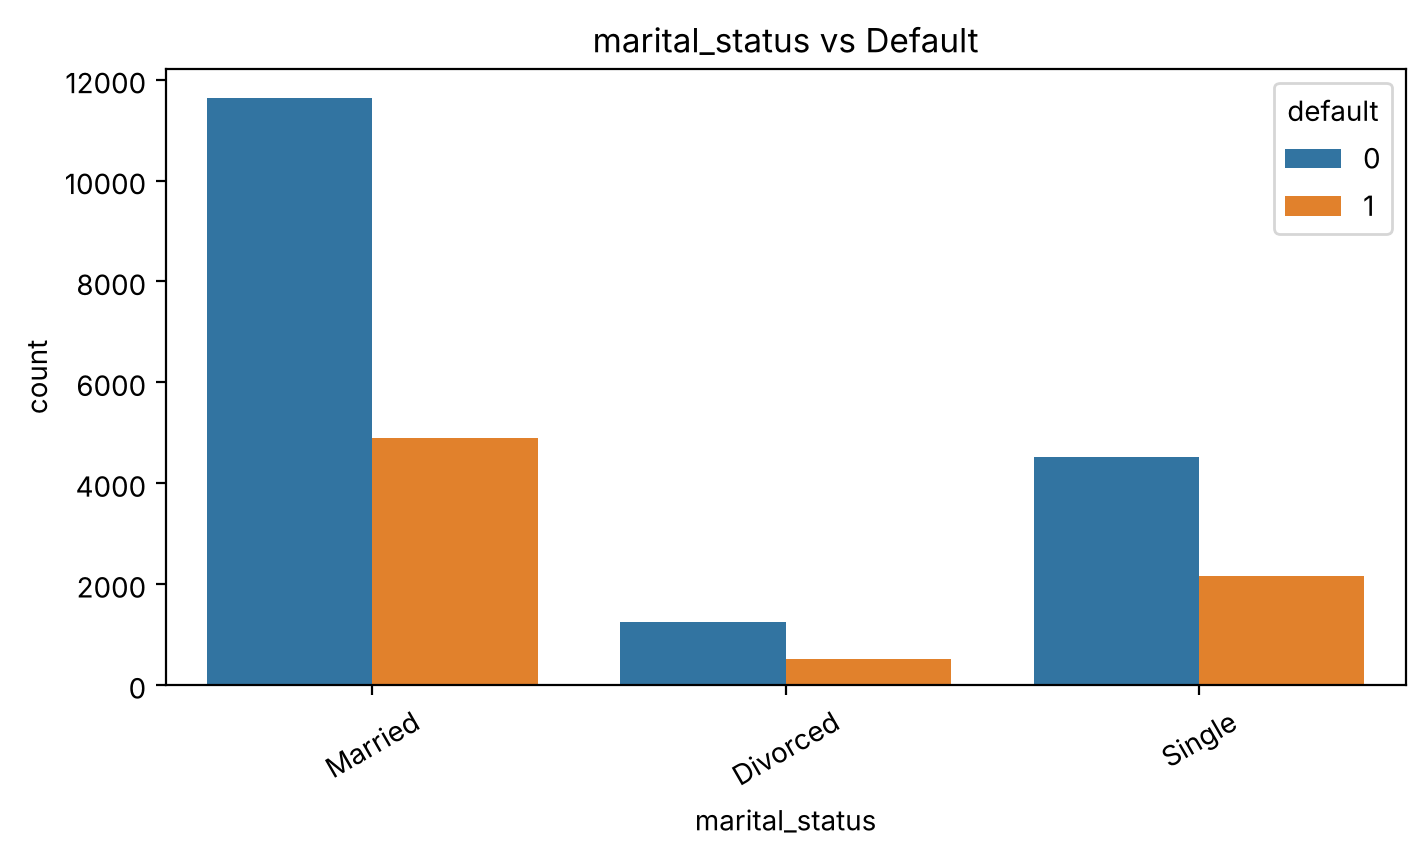

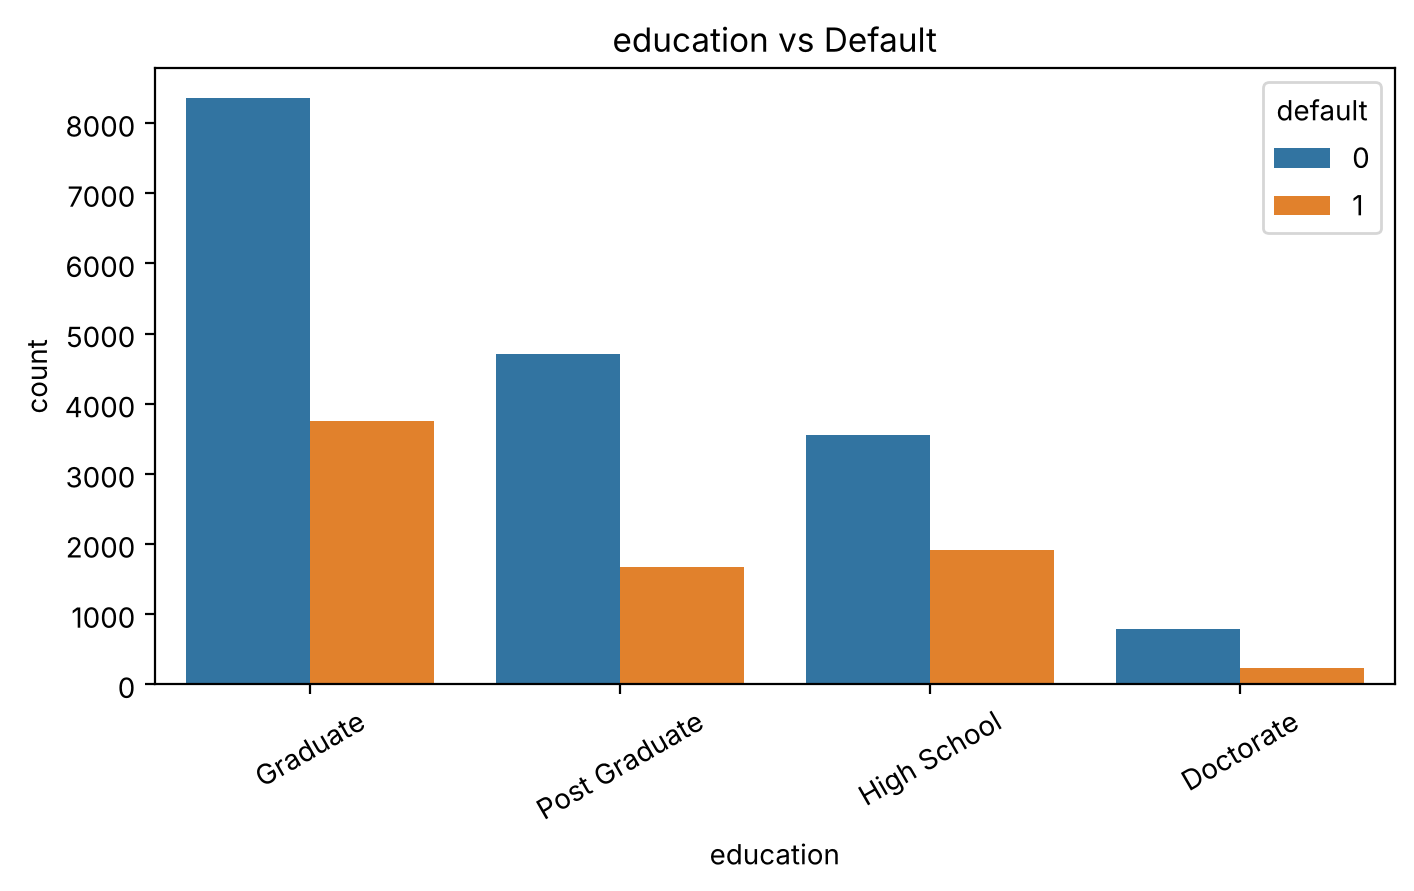

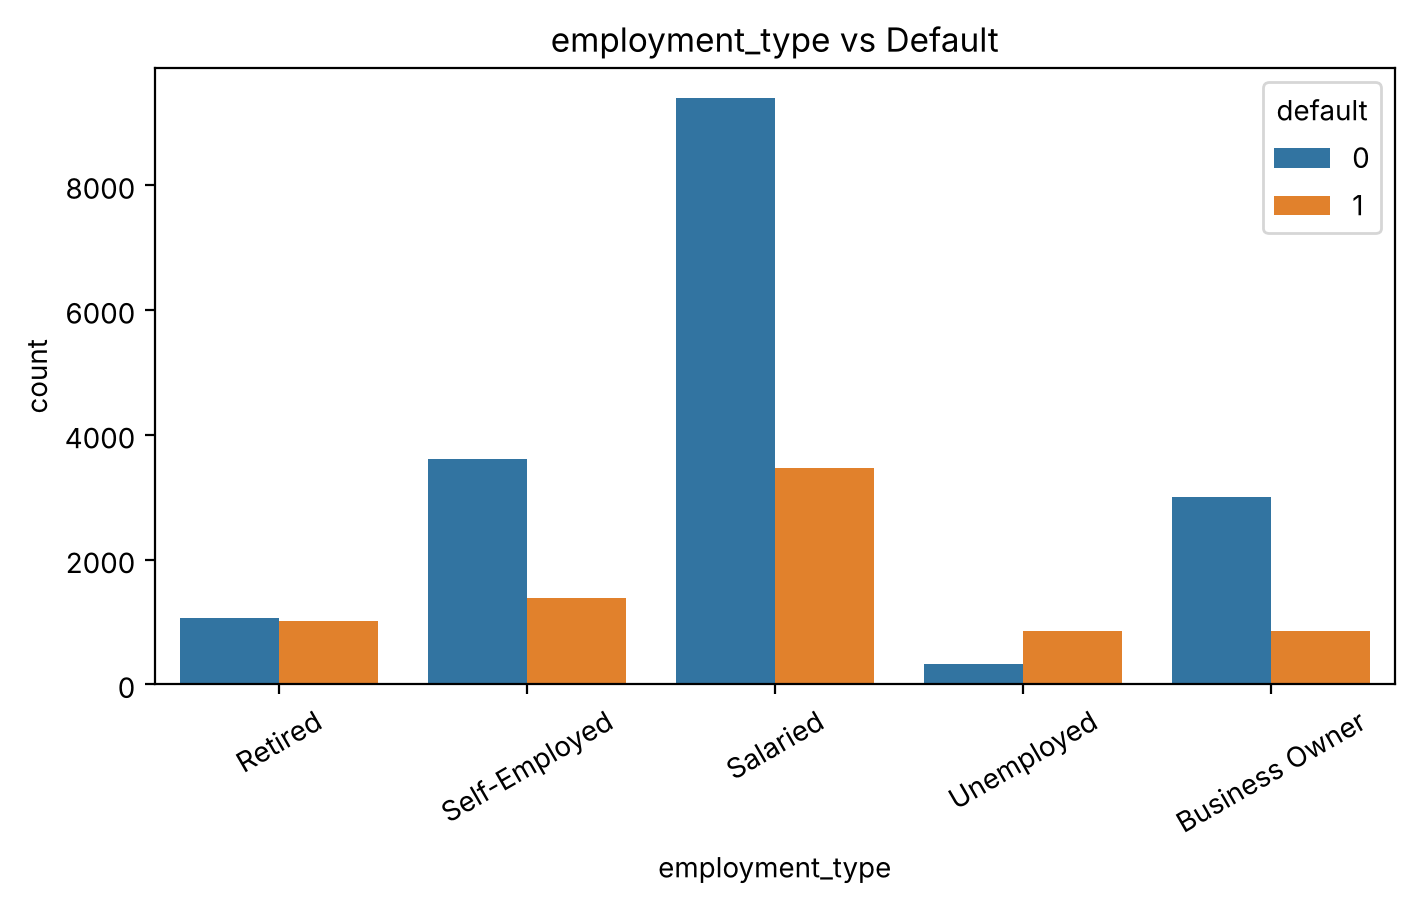

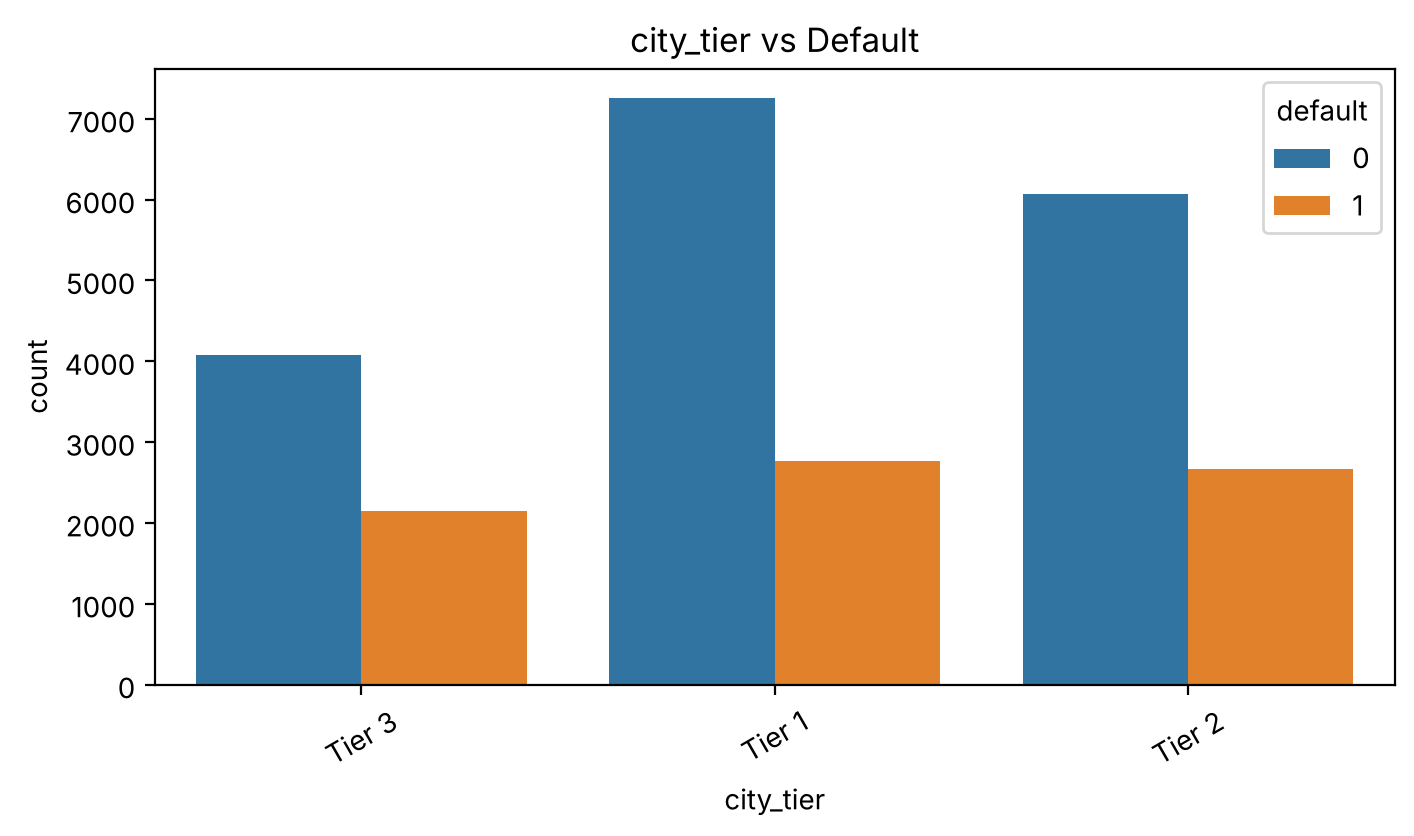

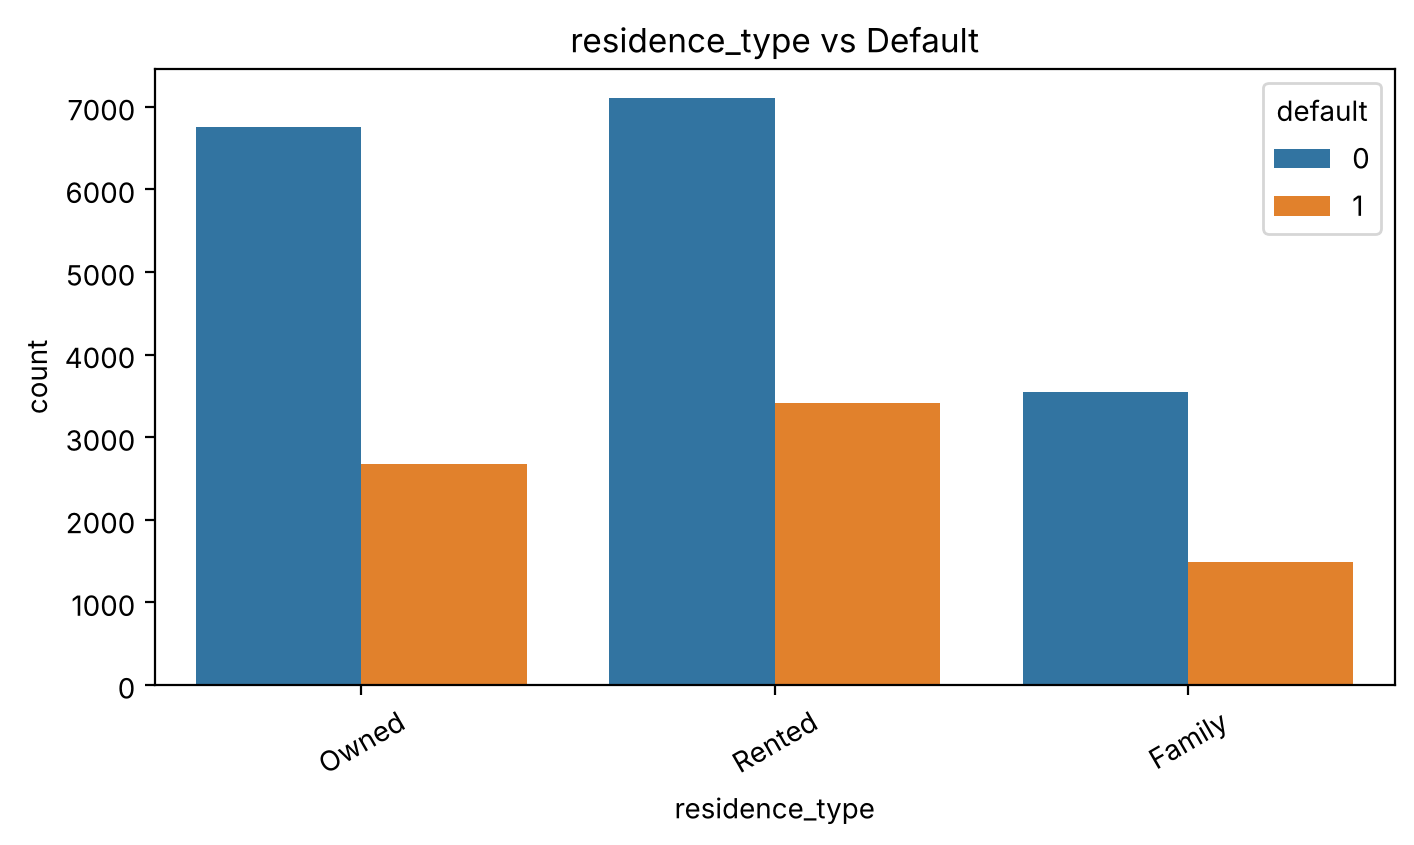

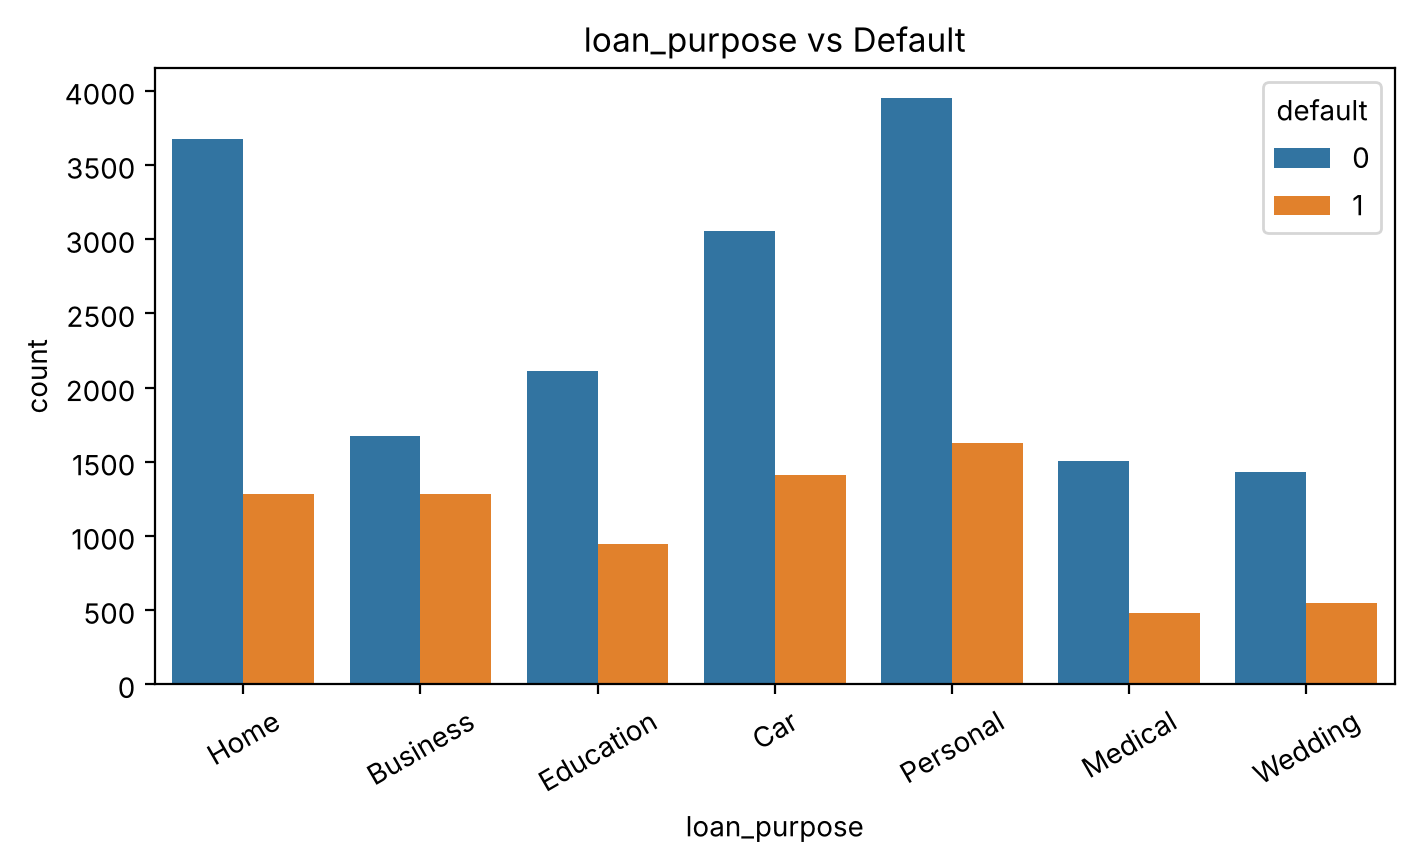

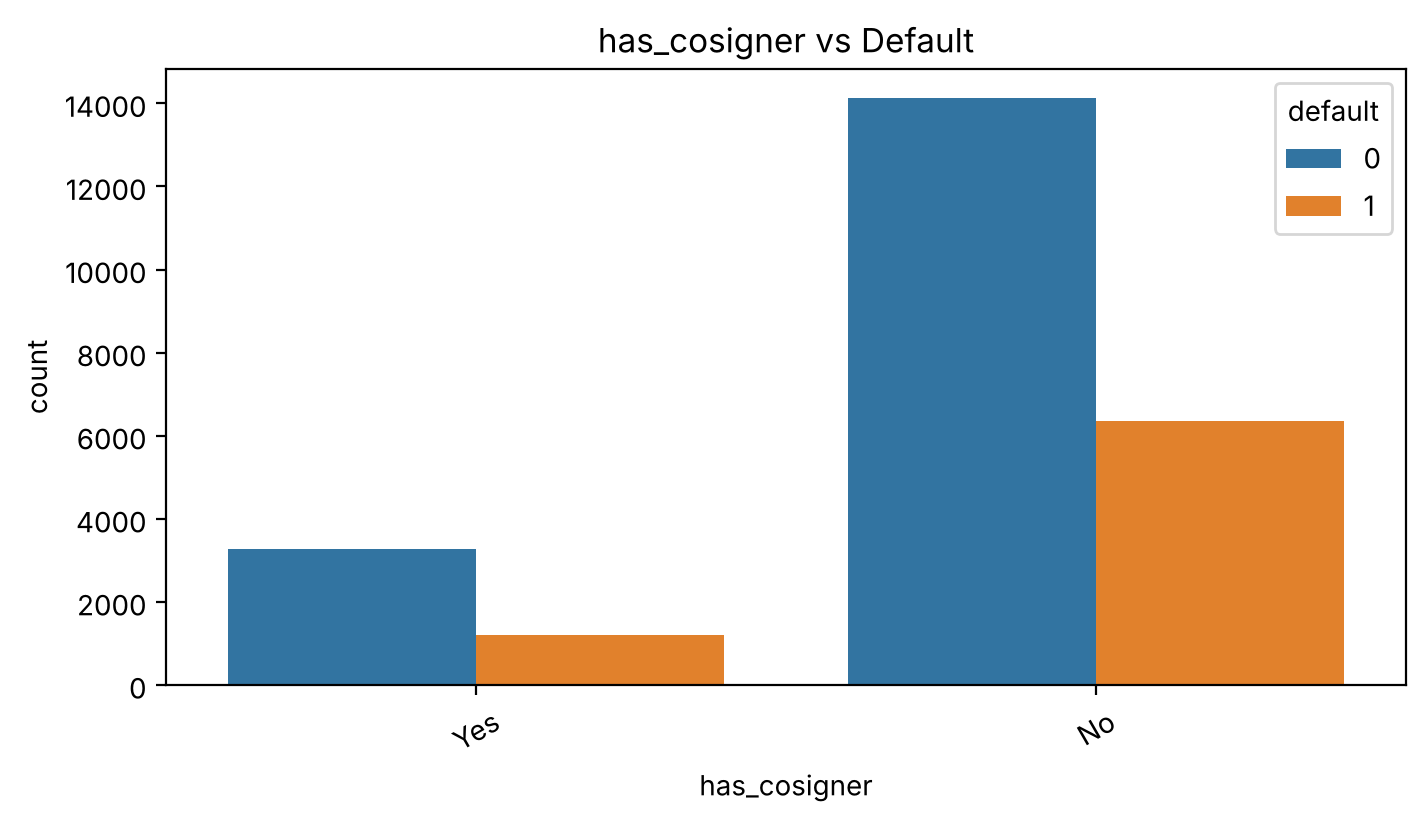

In [23]:
cat_cols = ['gender', 'marital_status', 'education', 'employment_type',
            'city_tier', 'residence_type', 'loan_purpose', 'has_cosigner']

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, hue='default', data=df)
    plt.title(col + ' vs Default')
    plt.xticks(rotation=30)
    plt.show()

Default rate (%) for each category

In [24]:
df.groupby('employment_type')['default'].mean() * 100

employment_type
Business Owner    22.196322
Retired           48.720425
Salaried          26.974757
Self-Employed     27.725545
Unemployed        72.455090
Name: default, dtype: float64

In [25]:
df.groupby('loan_purpose')['default'].mean() * 100

loan_purpose
Business     43.331077
Car          31.594268
Education    30.882353
Home         25.887813
Medical      24.282116
Personal     29.114378
Wedding      27.682186
Name: default, dtype: float64

In [26]:
df.groupby('has_cosigner')['default'].mean() * 100

has_cosigner
No     31.051655
Yes    26.975295
Name: default, dtype: float64

**Observations**
- **Unemployed** customers default the most.
- **Personal** and **Business** loans are riskier, **Home** loans are safer.
- Having a **cosigner** lowers the default rate.

### 4.5 Numeric columns vs Default

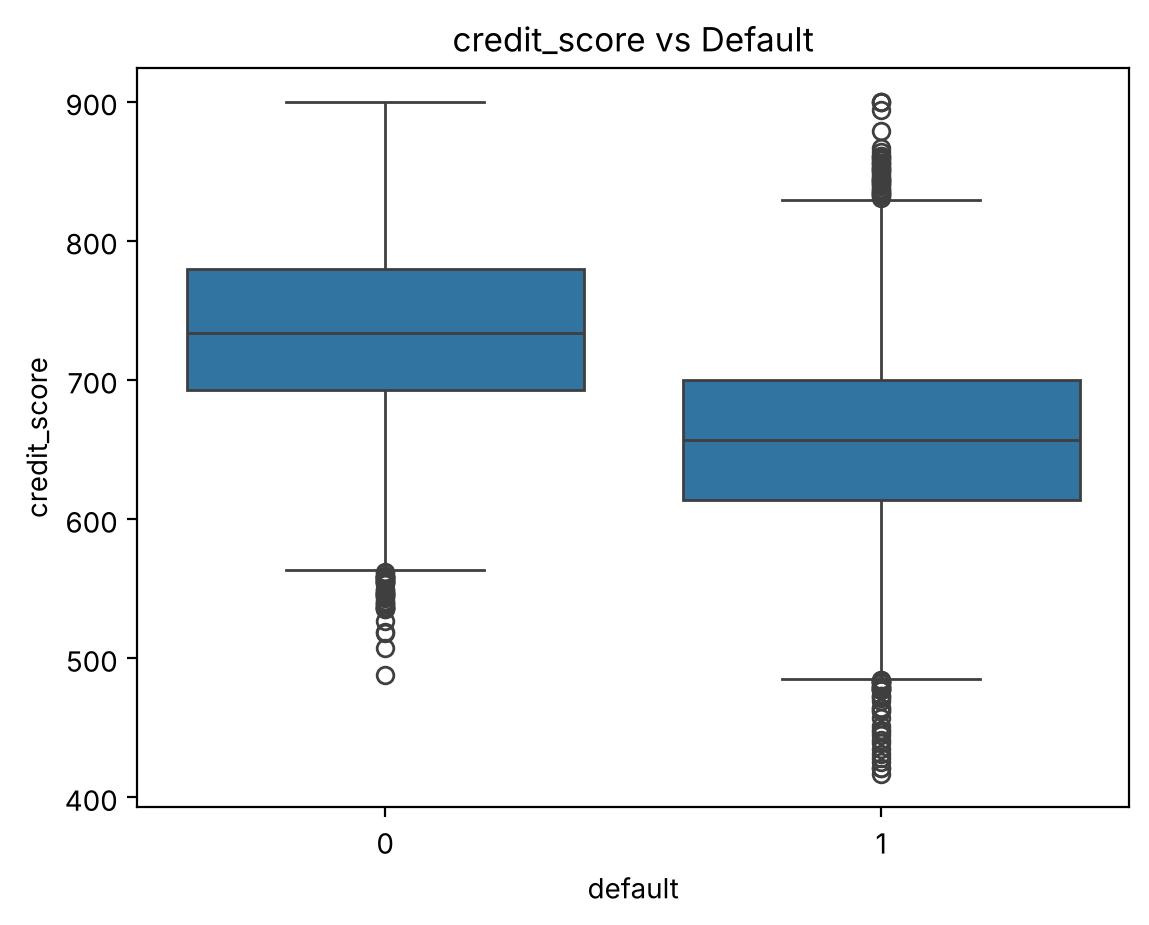

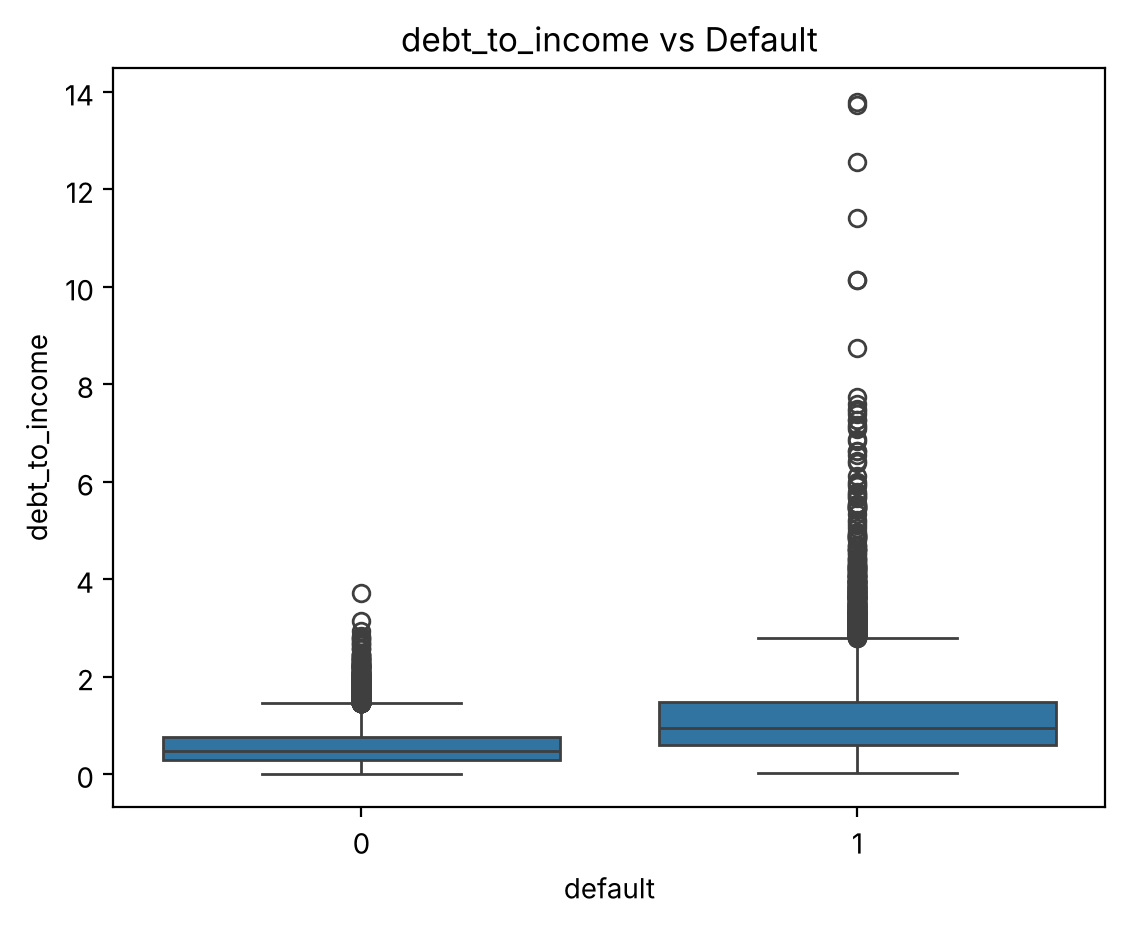

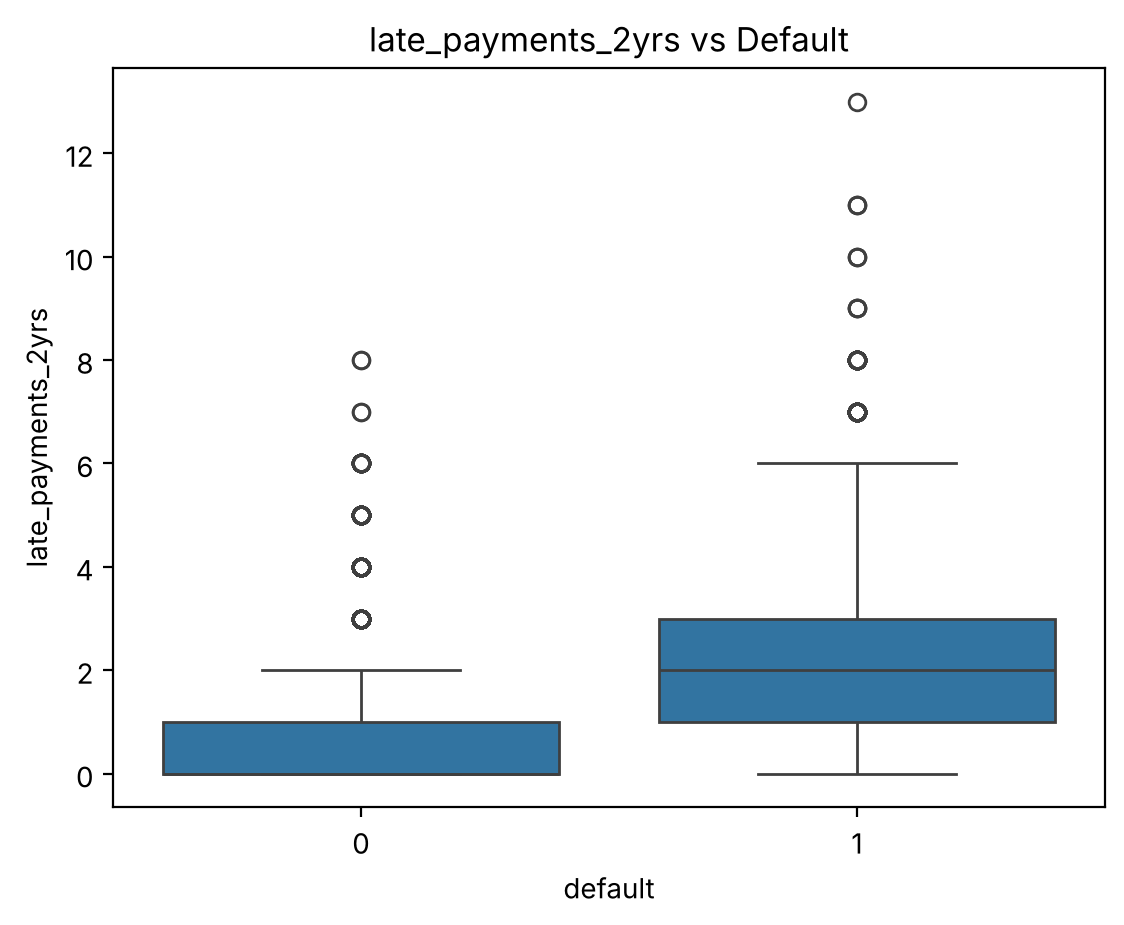

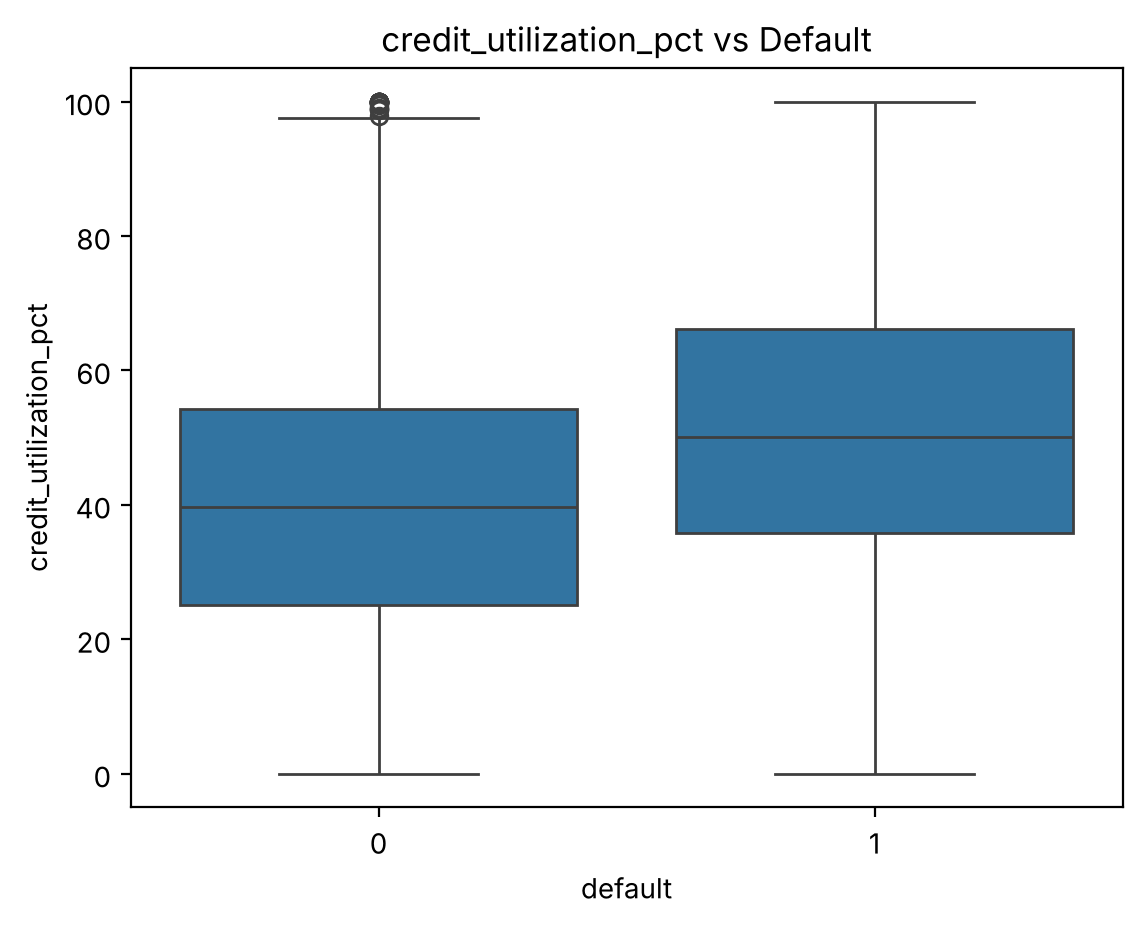

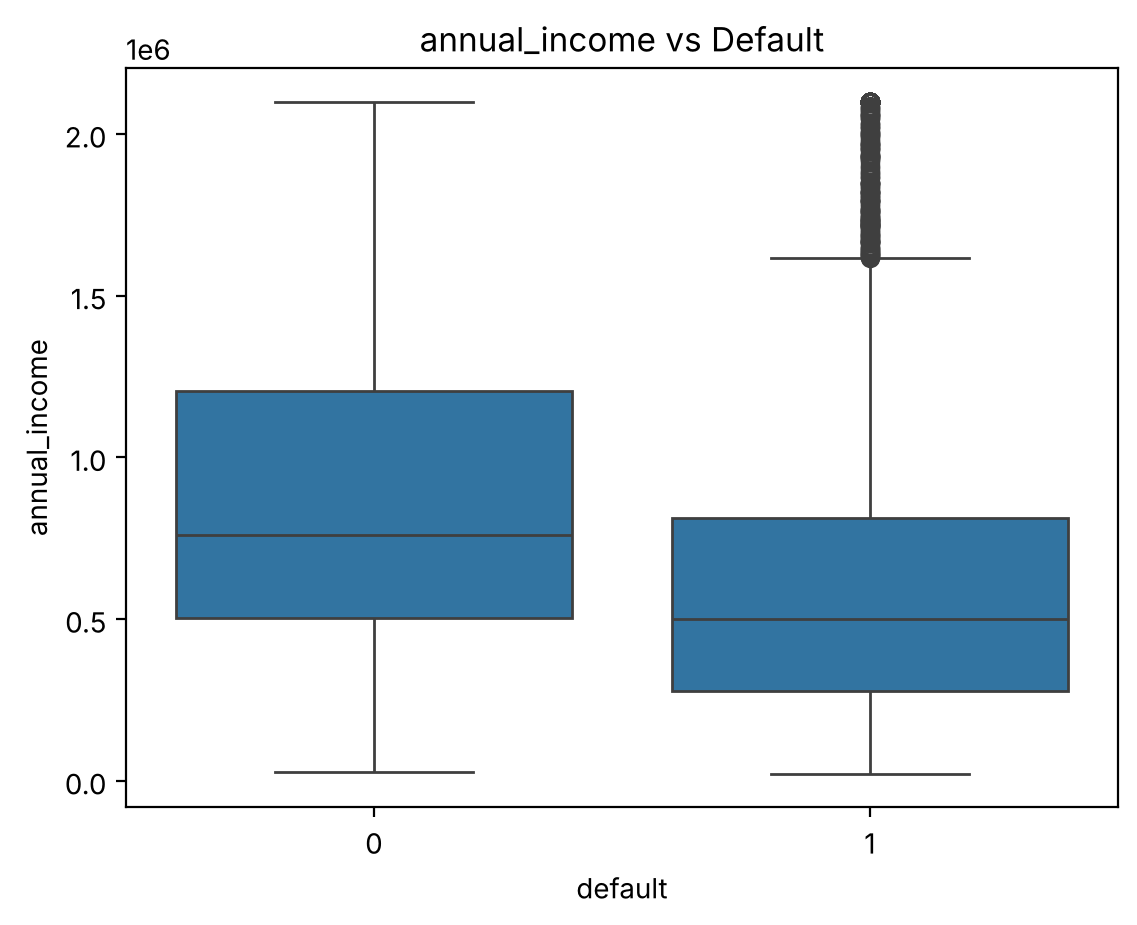

In [27]:
for col in ['credit_score', 'debt_to_income', 'late_payments_2yrs', 'credit_utilization_pct', 'annual_income']:
    sns.boxplot(x='default', y=col, data=df)
    plt.title(col + ' vs Default')
    plt.show()

**Observations**
- Defaulters have a **lower credit score**.
- Defaulters have a **higher debt-to-income ratio**, **more late payments** and **higher credit utilization**.

### 4.6 Correlation Heatmap

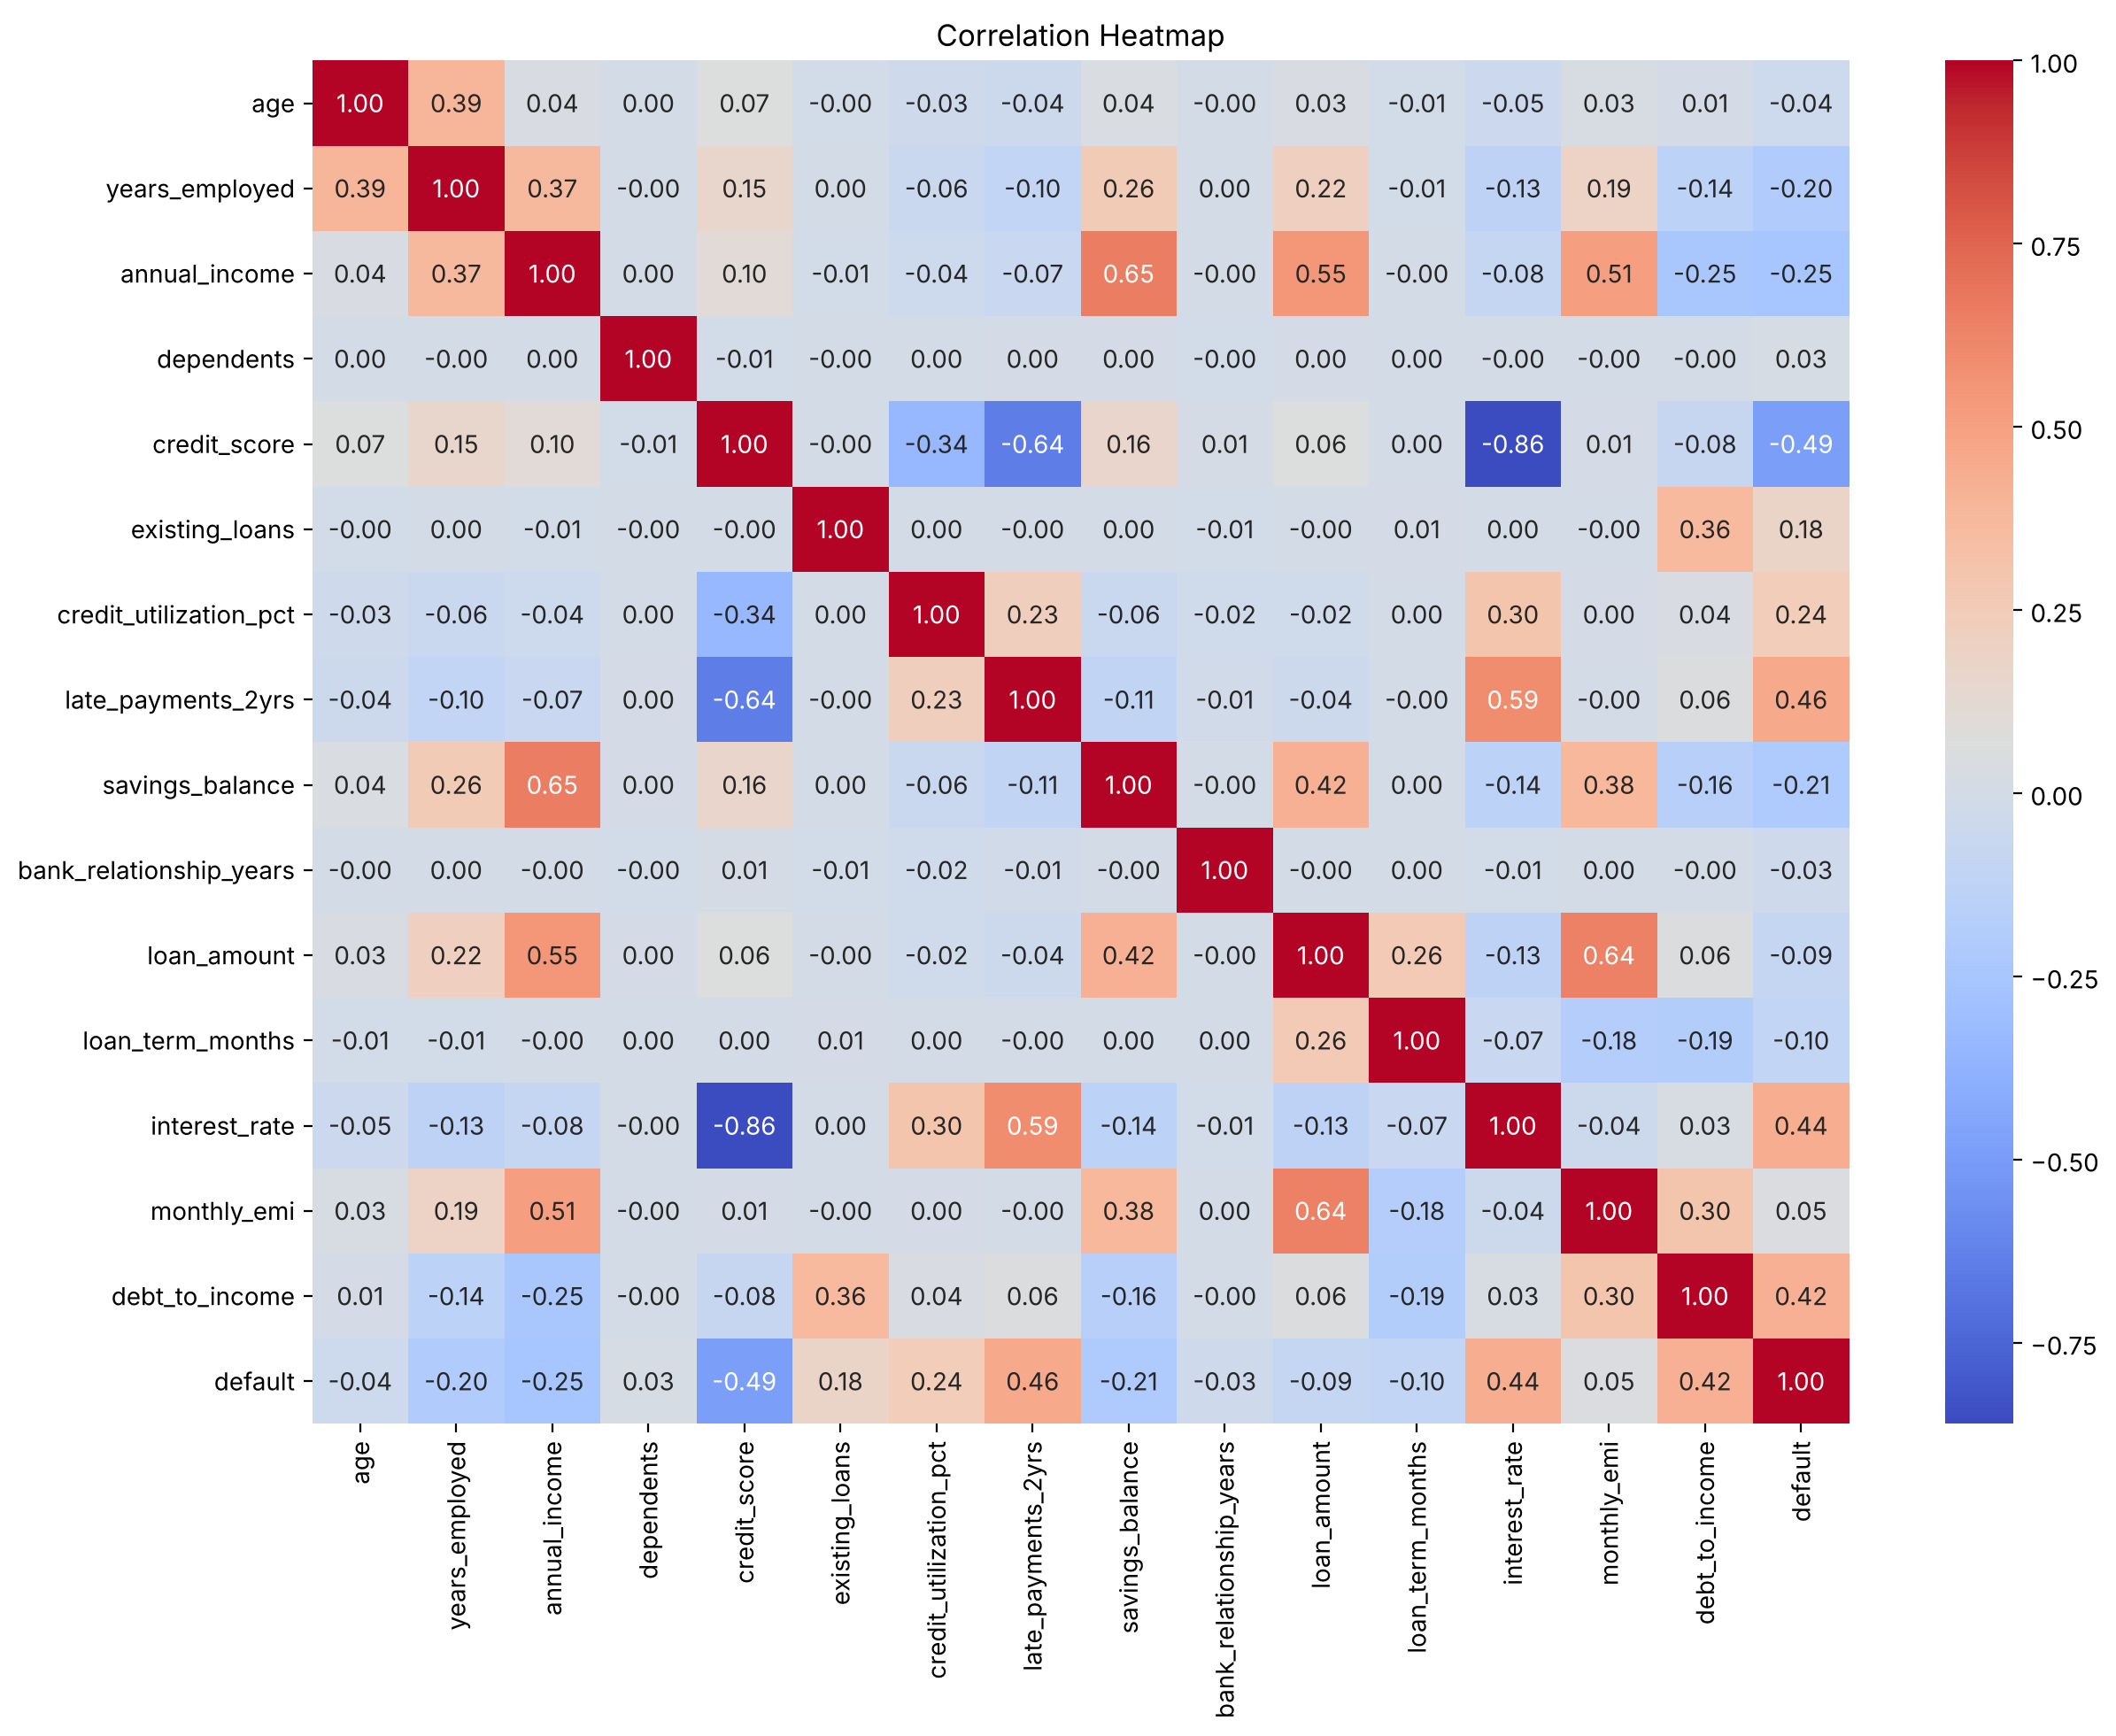

In [28]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Correlation of each numeric column with `default`

In [29]:
df.corr(numeric_only=True)['default'].sort_values(ascending=False)

default                    1.000000
late_payments_2yrs         0.459715
interest_rate              0.436587
debt_to_income             0.424081
credit_utilization_pct     0.240306
existing_loans             0.177057
monthly_emi                0.050945
dependents                 0.025006
bank_relationship_years   -0.029358
age                       -0.037091
loan_amount               -0.088621
loan_term_months          -0.102444
years_employed            -0.203943
savings_balance           -0.213867
annual_income             -0.252552
credit_score              -0.488811
Name: default, dtype: float64

## 5. Data Preparation

### 5.1 Drop columns that are not useful
`customer_id` is just an ID, so it does not help the model.

In [30]:
df = df.drop('customer_id', axis=1)

### 5.2 Log transform the skewed columns

In [31]:
df['annual_income'] = np.log1p(df['annual_income'])
df['loan_amount'] = np.log1p(df['loan_amount'])
df['savings_balance'] = np.log1p(df['savings_balance'])
df['monthly_emi'] = np.log1p(df['monthly_emi'])

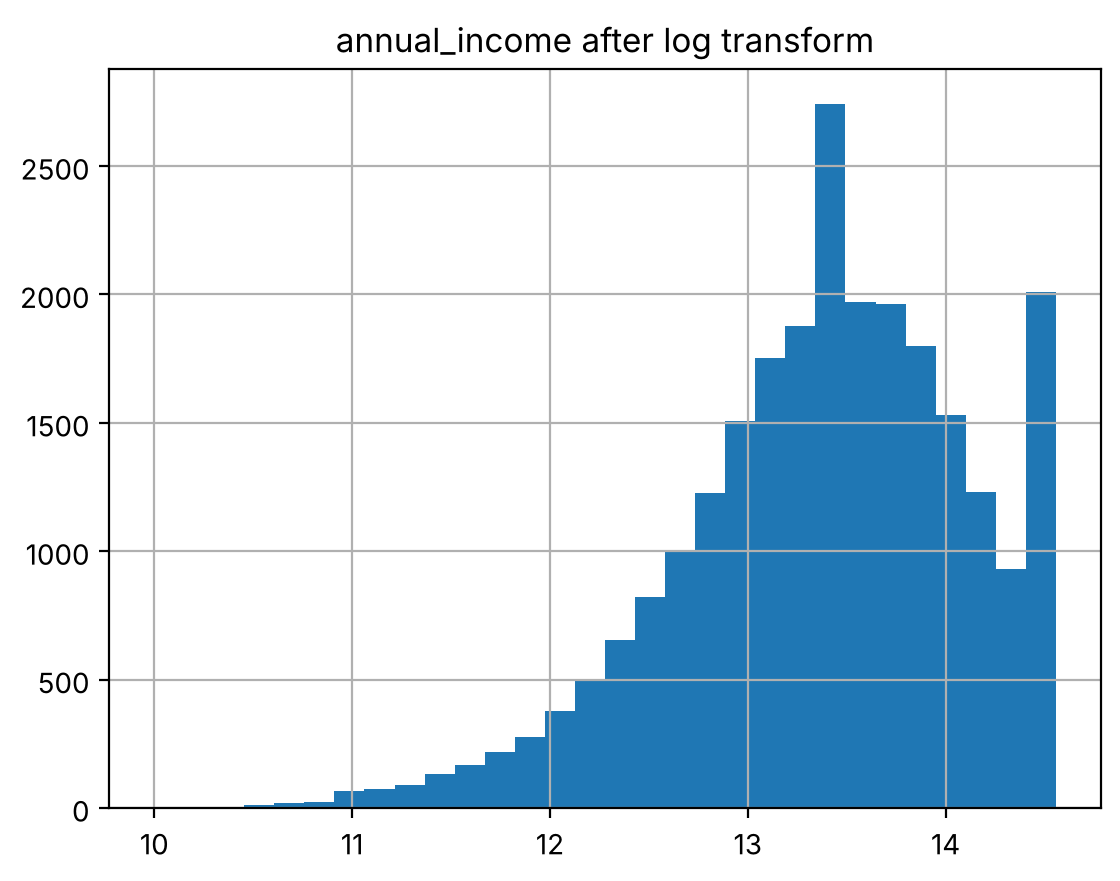

In [32]:
df['annual_income'].hist(bins=30)
plt.title('annual_income after log transform')
plt.show()

### 5.3 Encode categorical columns
`pd.get_dummies` turns each text column into 0/1 columns.

In [33]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
df.head()

,age,years_employed,annual_income,dependents,credit_score,existing_loans,credit_utilization_pct,late_payments_2yrs,savings_balance,bank_relationship_years,...,city_tier_Tier 3,residence_type_Owned,residence_type_Rented,loan_purpose_Car,loan_purpose_Education,loan_purpose_Home,loan_purpose_Medical,loan_purpose_Personal,loan_purpose_Wedding,has_cosigner_Yes
0,63,6.0,11.728045,0,708.0,1,64.7,2,9.532496,0,...,1,1,0,0,0,1,0,0,0,1
1,47,10.0,13.567050,2,778.0,0,54.6,0,11.483507,17,...,0,1,0,0,0,1,0,0,0,0
2,31,8.0,13.713479,3,779.0,3,52.8,0,13.758412,20,...,1,1,0,0,0,0,0,0,0,0
3,46,23.0,13.262127,4,760.0,2,22.6,0,11.584325,4,...,1,0,1,0,0,0,0,0,0,1
4,40,3.0,13.696728,0,666.0,0,29.1,0,9.998843,15,...,0,1,0,0,0,1,0,0,0,0


In [34]:
df.shape

(24975, 37)

## 6. Train-Test Split

**X** = input features, **y** = target (`default`)

In [35]:
X = df.drop('default', axis=1)
y = df['default']

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [37]:
X_train.shape, X_test.shape

((19980, 36), (4995, 36))

## 7. Feature Scaling : StandardScaler
StandardScaler makes every column have **mean = 0** and **std = 1**.
We **fit only on the training data**, then apply the same scaling to the test data.

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 8. Logistic Regression Model

In [39]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Predict on the test data

In [40]:
y_pred = model.predict(X_test)

## 9. Model Evaluation

### Accuracy

In [41]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

accuracy_score(y_test, y_pred)

0.8654654654654654

### Confusion Matrix

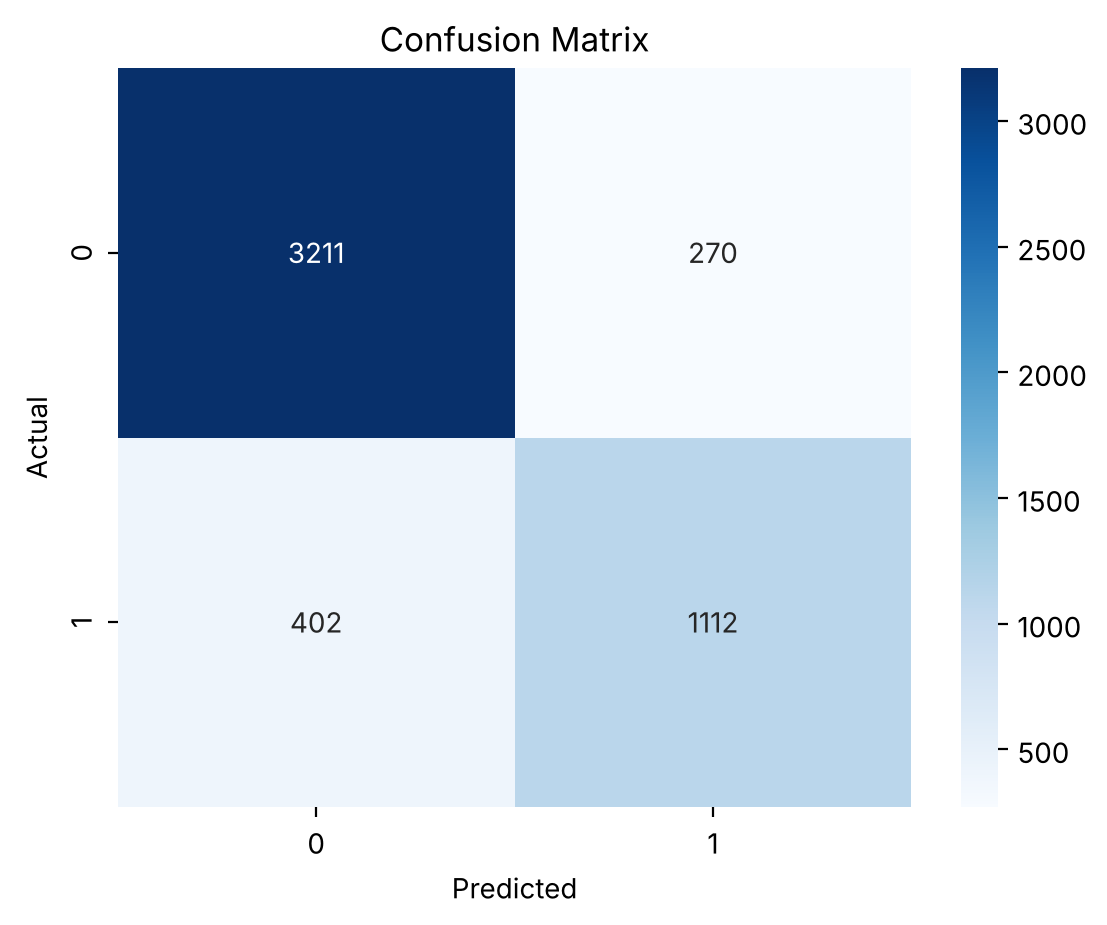

In [42]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Classification Report

In [43]:
report = classification_report(y_test, y_pred, output_dict=True)
pd.DataFrame(report).T

,precision,recall,f1-score,support
0,0.888735,0.922436,0.905272,3481.000000
1,0.804631,0.734478,0.767956,1514.000000
accuracy,0.865465,0.865465,0.865465,0.865465
macro avg,0.846683,0.828457,0.836614,4995.000000
weighted avg,0.863243,0.865465,0.863651,4995.000000


### ROC-AUC Score

In [44]:
y_prob = model.predict_proba(X_test)[:, 1]
roc_auc_score(y_test, y_prob)

0.927214047801293

## 10. Feature Importance (Coefficients)

A **positive** coefficient increases the chance of default; a **negative** coefficient lowers it.

In [45]:
coef = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_[0]})
coef = coef.sort_values('coefficient')
coef

,feature,coefficient
4,credit_score,-1.211542
2,annual_income,-0.404261
31,loan_purpose_Home,-0.223770
35,has_cosigner_Yes,-0.199694
1,years_employed,-0.181653
10,loan_amount,-0.156211
8,savings_balance,-0.143343
9,bank_relationship_years,-0.103133
34,loan_purpose_Wedding,-0.099496
29,loan_purpose_Car,-0.083415


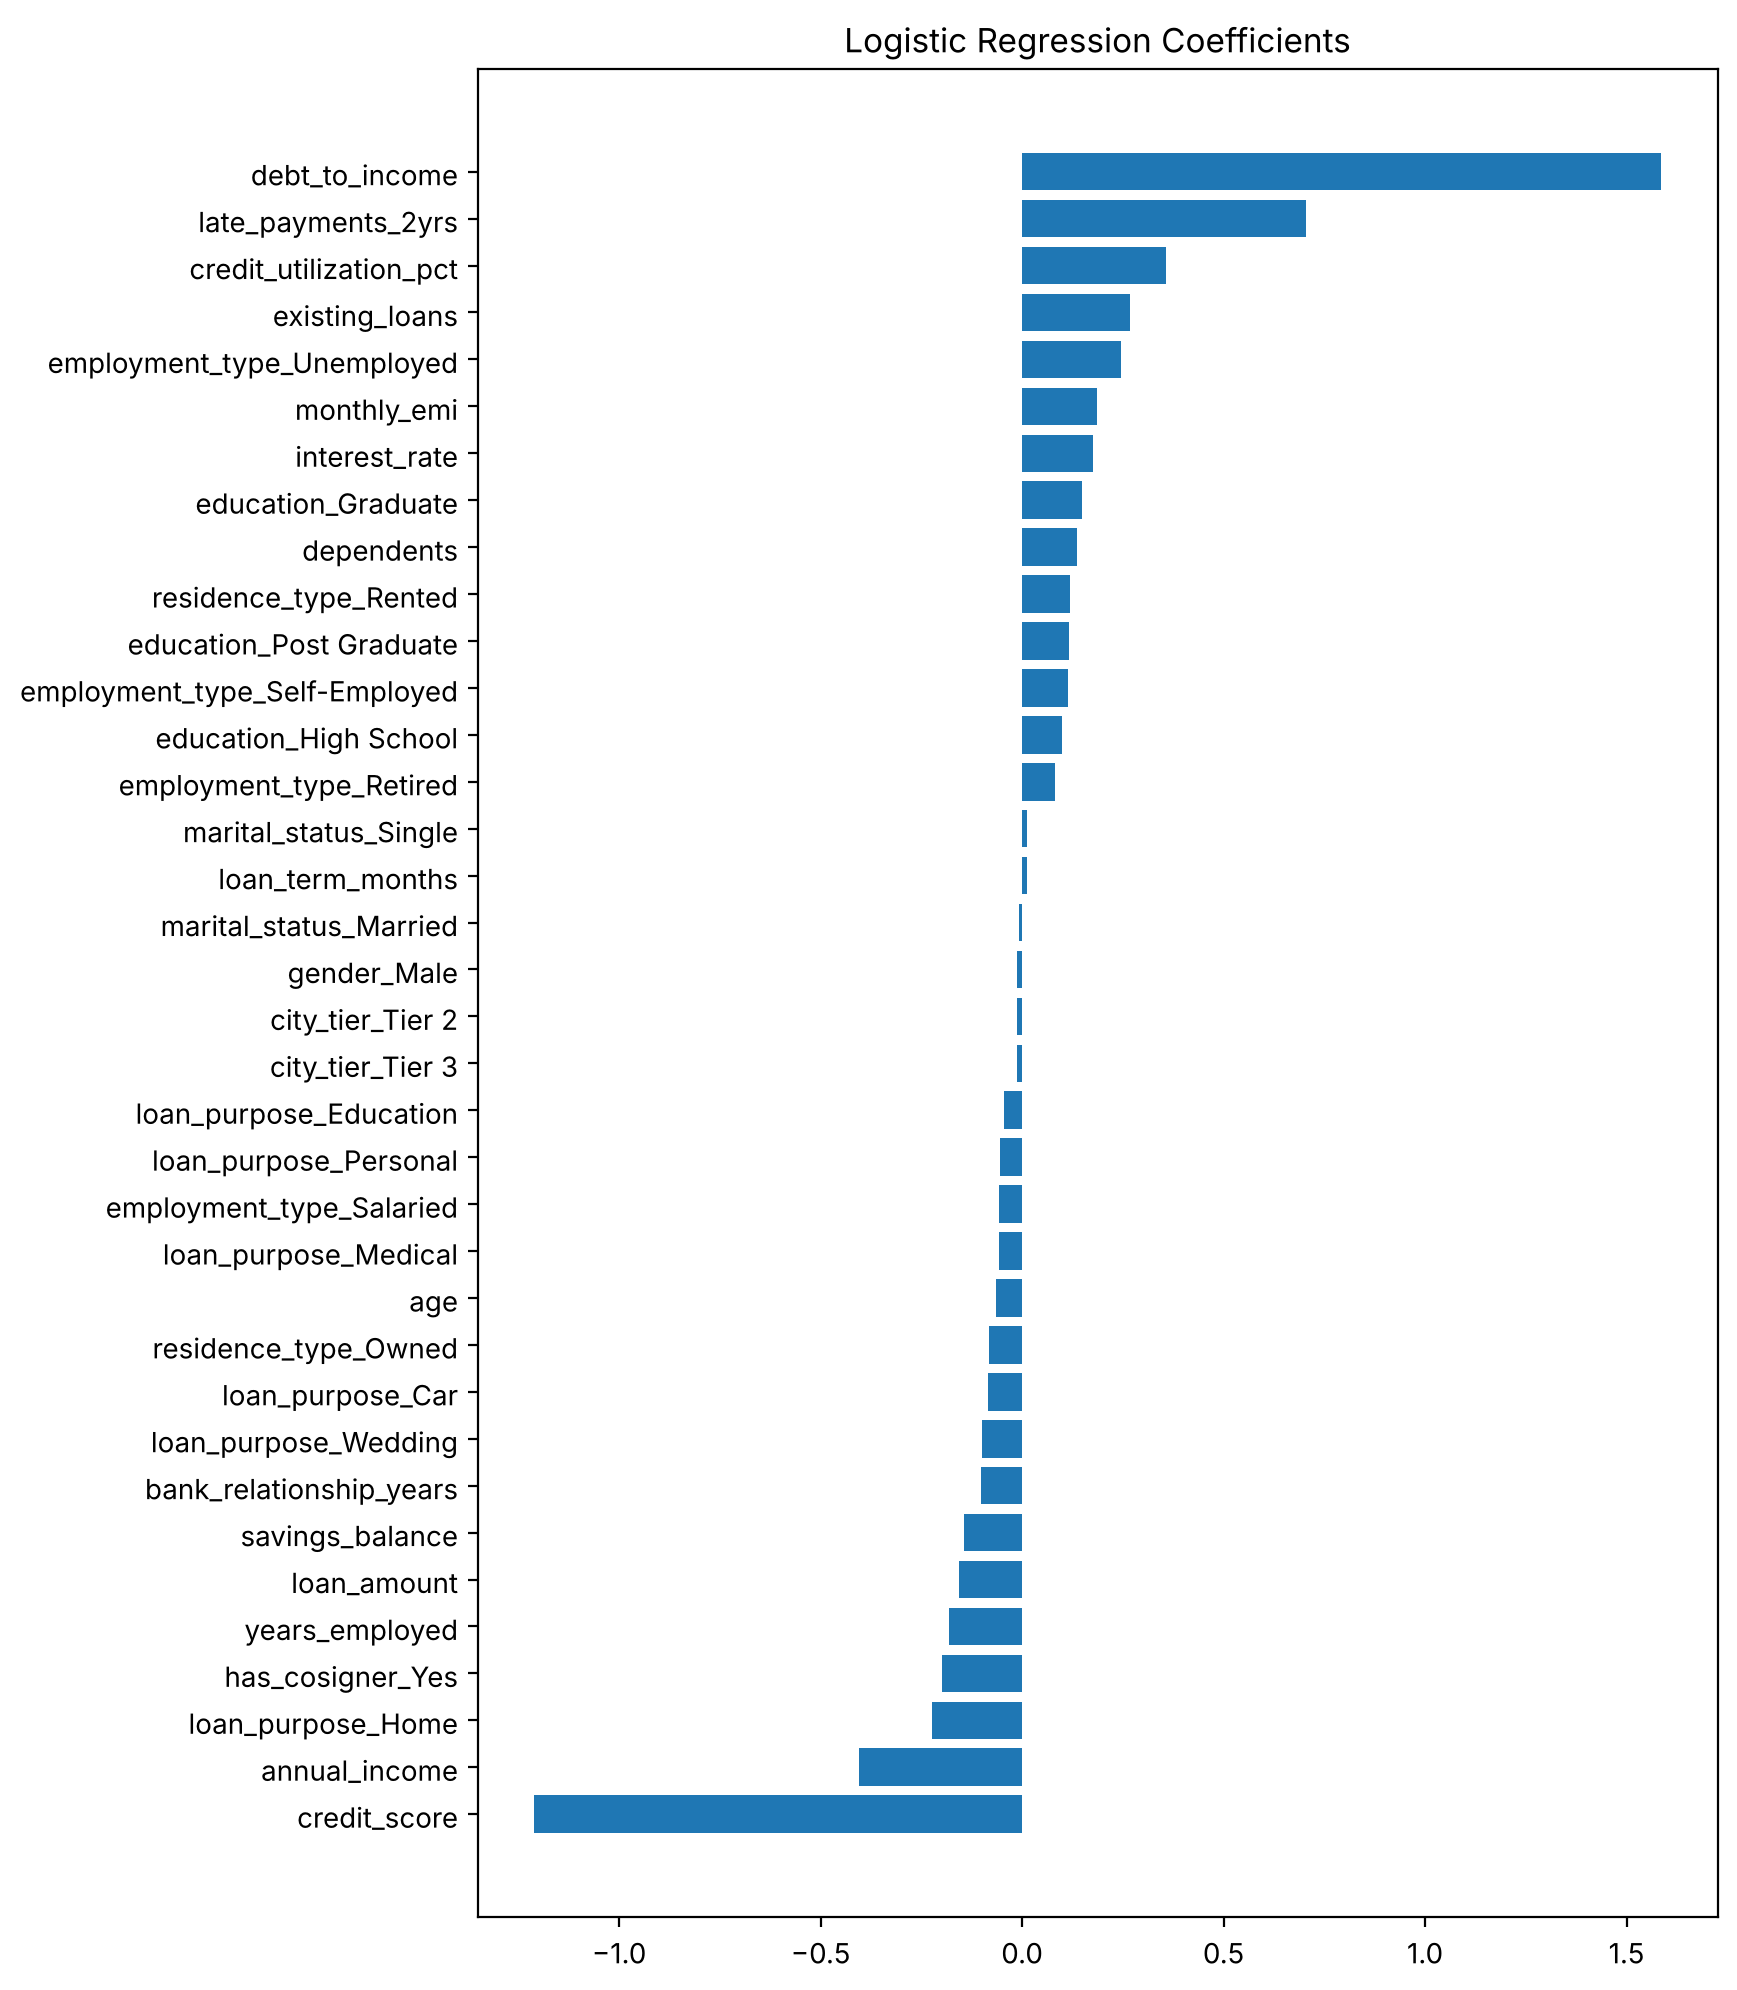

In [46]:
plt.figure(figsize=(8, 12))
plt.barh(coef['feature'], coef['coefficient'])
plt.title('Logistic Regression Coefficients')
plt.show()

## Conclusion
- The data was cleaned (duplicates, missing values, wrong ages, inconsistent text, outliers).
- EDA showed that **credit score, debt-to-income, late payments and credit utilization** are the strongest signals.
- Logistic Regression with StandardScaler gives about **86–87% accuracy** and **~0.92 ROC-AUC**.

**Next step:** try other models (Decision Tree, Random Forest, KNN, SVM, Naive Bayes, XGBoost) on the same `X_train`, `X_test` and compare.